# ENA_2025_Modulo_14


## 1. Objetivo

Exploramos las variables de Inocuidad de la ENA 2025 mediante tablas, gráficos y comparaciones territoriales, considerando las respuestas registradas en el módulo 14.

## 2. Lectura

### 2.1. Importación de librerías

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

### 2.2. Lectura de datos y diccionario

Leemos el archivo Parquet del módulo 14 y su diccionario de variables.

In [2]:
# Módulo 14
df_inocuidad = pd.read_parquet("../data/raw/14_CAP600.parquet")

# Diccionario del módulo 14
df_diccionario_14 = pd.read_excel("../data/raw/DICC_ENA_2025.xlsx", sheet_name="14_CAP600")

### 3.1. Primeras filas y dimensiones

Observamos los primeros registros y las dimensiones del módulo 14.

In [3]:
display(df_inocuidad.head())
print("\nFilas y columnas:", df_inocuidad.shape)

,ANIO,CCDD,NOMBREDD,CCPP,NOMBREPV,CCDI,NOMBREDI,NSEGM,ID_PROD,UA,...,P607,P608,P609,P610_1,P610_2,P610_3,P610_4,P610_5,P610_6,OMICAP600
0,2025,1.0,AMAZONAS,1.0,CHACHAPOYAS,1.0,CHACHAPOYAS,30001,1,1,...,1.0,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,
1,2025,1.0,AMAZONAS,1.0,CHACHAPOYAS,1.0,CHACHAPOYAS,30001,2,2,...,1.0,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,
2,2025,1.0,AMAZONAS,1.0,CHACHAPOYAS,1.0,CHACHAPOYAS,30001,3,3,...,2.0,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,
3,2025,1.0,AMAZONAS,1.0,CHACHAPOYAS,1.0,CHACHAPOYAS,30001,4,4,...,1.0,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,
4,2025,1.0,AMAZONAS,1.0,CHACHAPOYAS,1.0,CHACHAPOYAS,30002,1,1,...,1.0,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,



Filas y columnas: (40020, 61)


### 3.2. Columnas, tipos, nulos y textos vacíos

Revisamos los nombres de las columnas, sus tipos de datos y valores nulos. También los valores de `OMICAP600` para identificar posibles textos vacíos.

In [4]:
print("Columnas:", df_inocuidad.columns.tolist())
print("\n ")

# Tipos y valores no nulos
df_inocuidad.info(verbose=True, show_counts=True)

Columnas: ['ANIO', 'CCDD', 'NOMBREDD', 'CCPP', 'NOMBREPV', 'CCDI', 'NOMBREDI', 'NSEGM', 'ID_PROD', 'UA', 'RESFIN', 'REGION', 'ESTRATO', 'FACTOR_PRODUCTOR', 'CODIGO', 'P101A', 'P142_1', 'P142_2', 'P142_3', 'P601_1', 'P601_2', 'P601_3', 'P601_4', 'P601_5', 'P601_6', 'P601_7', 'P602_1', 'P602_2', 'P602_3', 'P602_4', 'P602_5', 'P602_6', 'P602_7', 'P602_8', 'P602_9', 'P603', 'P604', 'P605_1', 'P605_2', 'P605_3', 'P605_4', 'P605_5', 'P605_6', 'P605A', 'P606_1', 'P606_2', 'P606_3', 'P606_4', 'P606_5', 'P606_6', 'P606_7', 'P607', 'P608', 'P609', 'P610_1', 'P610_2', 'P610_3', 'P610_4', 'P610_5', 'P610_6', 'OMICAP600']

 
<class 'pandas.DataFrame'>
RangeIndex: 40020 entries, 0 to 40019
Data columns (total 61 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ANIO              40020 non-null  int64  
 1   CCDD              38449 non-null  float64
 2   NOMBREDD          38449 non-null  str    
 3   CCPP              38449 non-null  float64


In [5]:
# Valores nulos por columna
display(df_inocuidad.isna().sum().to_frame("Nulos"))

,Nulos
ANIO,0
CCDD,1571
NOMBREDD,1571
CCPP,1571
NOMBREPV,1571
...,...
P610_3,39385
P610_4,39385
P610_5,39385
P610_6,39385


In [6]:
# Frecuencias de OMICAP600
display(df_inocuidad["OMICAP600"].value_counts(dropna=False))

OMICAP600
    40020
Name: count, dtype: int64

In [7]:
# Textos vacíos o espacios en OMICAP600
textos_vacios = df_inocuidad["OMICAP600"].fillna("").astype(str).str.strip().eq("")

print("Textos vacíos u espacios:", (textos_vacios & df_inocuidad["OMICAP600"].notna()).sum())

Textos vacíos u espacios: 40020


### 4.1. Identificación y selección de la llave

El proyecto establece una llave compuesta de siete campos para relacionar los módulos de la ENA. Verificamos cuáles están disponibles en el módulo 14 y revisamos la diferencia entre `CLUSTER` y `NSEGM`.

In [8]:
# Llave establecida en el proyecto
llave_oficial = ["ANIO", "CCDD", "CCPP", "CCDI", "CLUSTER", "ID_PROD", "UA"]

# Identificadores disponibles en el módulo
print("Columnas del módulo:", df_inocuidad.columns.tolist())

# Llave oficial vs las columnas del módulo
print("\nCampos de la llave presentes:", [col for col in llave_oficial if col in df_inocuidad.columns])
print("Campos de la llave ausentes:", [col for col in llave_oficial if col not in df_inocuidad.columns])

Columnas del módulo: ['ANIO', 'CCDD', 'NOMBREDD', 'CCPP', 'NOMBREPV', 'CCDI', 'NOMBREDI', 'NSEGM', 'ID_PROD', 'UA', 'RESFIN', 'REGION', 'ESTRATO', 'FACTOR_PRODUCTOR', 'CODIGO', 'P101A', 'P142_1', 'P142_2', 'P142_3', 'P601_1', 'P601_2', 'P601_3', 'P601_4', 'P601_5', 'P601_6', 'P601_7', 'P602_1', 'P602_2', 'P602_3', 'P602_4', 'P602_5', 'P602_6', 'P602_7', 'P602_8', 'P602_9', 'P603', 'P604', 'P605_1', 'P605_2', 'P605_3', 'P605_4', 'P605_5', 'P605_6', 'P605A', 'P606_1', 'P606_2', 'P606_3', 'P606_4', 'P606_5', 'P606_6', 'P606_7', 'P607', 'P608', 'P609', 'P610_1', 'P610_2', 'P610_3', 'P610_4', 'P610_5', 'P610_6', 'OMICAP600']

Campos de la llave presentes: ['ANIO', 'CCDD', 'CCPP', 'CCDI', 'ID_PROD', 'UA']
Campos de la llave ausentes: ['CLUSTER']


In [9]:
# Llave candidata
llave_14 = ["ANIO", "CCDD", "CCPP", "CCDI", "NSEGM", "ID_PROD", "UA"]

print("Llave candidata:", llave_14)
print("Campos disponibles:", all(col in df_inocuidad.columns for col in llave_14))

Llave candidata: ['ANIO', 'CCDD', 'CCPP', 'CCDI', 'NSEGM', 'ID_PROD', 'UA']
Campos disponibles: True


### 4.2. Valores faltantes y repeticiones

Revisamos los identificadores incompletos y verificamos si existen combinaciones repetidas de la llave candidata y de la identificación de UA.

In [10]:
# Valores nulos por identificador
print(df_inocuidad[llave_14].isna().sum())

# Registros con algún identificador faltante
print("\nRegistros incompletos:", df_inocuidad[llave_14].isna().any(axis=1).sum())

ANIO          0
CCDD       1571
CCPP       1571
CCDI       1571
NSEGM         0
ID_PROD       0
UA            0
dtype: int64

Registros incompletos: 1571


In [11]:
# Registros con todos los identificadores presentes
df_llave_completa = df_inocuidad.dropna(subset=llave_14)

print("Registros con llave completa:", len(df_llave_completa))
print("Combinaciones repetidas:", df_llave_completa.duplicated(subset=llave_14).sum())

Registros con llave completa: 38449
Combinaciones repetidas: 0


In [12]:
# Identificación de UA sin ID_PROD
llave_ua = ["ANIO", "CCDD", "CCPP", "CCDI", "NSEGM", "UA"]

# Comprobar combinaciones repetidas
repeticiones_ua = df_llave_completa.duplicated(subset=llave_ua, keep=False)

print("Filas con identificación de UA repetida:", repeticiones_ua.sum())

# Mostrar registros repetidos, si existen
if repeticiones_ua.any():
    display(df_llave_completa.loc[repeticiones_ua, llave_14].head(10))

Filas con identificación de UA repetida: 0


### 4.3. Delimitación de registros

Excluimos los registros sin nombre de departamento, según el criterio del proyecto. Comprobamos el año y el resultado final de la encuesta sin modificar los datos originales.

En la tabla de control, `CODIGO` distingue personas naturales (1) y empresas (2). Para `P608`, 1 significa «Sí» y 2 «No». `NOMBREDD presente` indica si el registro tiene nombre de departamento.

In [13]:
# Control de P608 antes del filtro geográfico
display(pd.crosstab(
    [df_inocuidad["CODIGO"], df_inocuidad["NOMBREDD"].notna()],
    df_inocuidad["P608"],
    rownames=["CODIGO", "NOMBREDD presente"],
    colnames=["P608"],
))

,P608,1,2
CODIGO,NOMBREDD presente,,
1,True,147,38302
2,False,488,1083


In [14]:
# Registros sin departamento
sin_departamento = df_inocuidad["NOMBREDD"].isna().sum()

# Crear un .copy .capy para próximos análisis
df_analisis = df_inocuidad[df_inocuidad["NOMBREDD"].notna()].copy()

print("Registros sin departamento:", sin_departamento)
print("Registros disponibles para análisis:", len(df_analisis))

# Verificar año y resultado final
print("\nAños:")
print(df_analisis["ANIO"].value_counts(dropna=False))

print("\nResultado final de encuesta:")
print(df_analisis["RESFIN"].value_counts(dropna=False))

Registros sin departamento: 1571
Registros disponibles para análisis: 38449

Años:
ANIO
2025    38449
Name: count, dtype: int64

Resultado final de encuesta:
RESFIN
1    38449
Name: count, dtype: int64


## 5. Reconocimiento del módulo completo
### 5.1. Lectura documental

Consultamos el diccionario completo del módulo 14 para identificar las preguntas, sus respuestas y las condiciones de aplicación.

In [15]:
columnas_diccionario = ["NOMBRE DE LA VARIABLE", "DESCRIPCIÓN DE LAS VARIABLES", "VALOR"]

# Show diccionario en grupos de 25 filas
for inicio in range(0, len(df_diccionario_14), 25):
    display(df_diccionario_14.iloc[inicio:inicio + 25][columnas_diccionario])

,NOMBRE DE LA VARIABLE,DESCRIPCIÓN DE LAS VARIABLES,VALOR
0,ANIO,AÑO,NaN
1,CCDD,Código de Departamento,NaN
2,NOMBREDD,Nombre de Departamento,NaN
3,CCPP,Código de Provincia,NaN
4,NOMBREPV,Nombre de la Provincia,NaN
5,CCDI,Código del Distrito,NaN
6,NOMBREDI,Nombre del Distrito,NaN
7,NSEGM,NÚMERO CORRELATIVO EN SECUENCIA,NaN
8,NaN,SERPENTIN POR REGIÓN,NaN
9,ID_PROD,Identificador de la Unidad Agropecuaria,NaN


,NOMBRE DE LA VARIABLE,DESCRIPCIÓN DE LAS VARIABLES,VALOR
25,NaN,NaN,4 ¿Sociedad comercial de responsabilidad limi...
26,NaN,SU CONDICIÓN JURÍDICA COMO PRODUCTOR O EMPRESA...,6 ¿Cooperativa agraria?
27,P101A,NaN,7 ¿Sociedad anónima?
28,NaN,NaN,8 ¿Otro?
29,P142_1,"EN LOS ÚLTIMOS 12 MESES, DE…..A LA",NaN
30,NaN,EMPRESA/UD. REALIZÓ ACTIVIDAD: ¿Agrícola?,NaN
31,P142_2,"EN LOS ÚLTIMOS 12 MESES, DE…..A LA",NaN
32,NaN,EMPRESA/UD. REALIZÓ ACTIVIDAD: ¿Pecuaria?,NaN
33,NaN,"EN LOS ÚLTIMOS 12 MESES, DE…..A LA",NaN
34,P142_3,EMPRESA/UD. REALIZÓ ACTIVIDAD: NO REALIZÓ ACTI...,NaN


,NOMBRE DE LA VARIABLE,DESCRIPCIÓN DE LAS VARIABLES,VALOR
50,P602_4,¿QUÉ HACE CON LOS RESIDUOS DE SUS,NaN
51,NaN,ANIMALES DE CRIANZA? 4. Usa como abono,NaN
52,NaN,¿QUÉ HACE CON LOS RESIDUOS DE SUS,NaN
53,P602_5,ANIMALES DE CRIANZA? 5. Usa como combustible,NaN
54,P602_6,¿QUÉ HACE CON LOS RESIDUOS DE SUS,NaN
55,NaN,ANIMALES DE CRIANZA? 6. Deja en el campo,NaN
56,P602_7,¿QUÉ HACE CON LOS RESIDUOS DE SUS ANIMALES DE ...,NaN
57,NaN,¿QUÉ HACE CON LOS RESIDUOS DE SUS ANIMALES DE ...,NaN
58,P602_8,APÍCOLA,NaN
59,NaN,¿QUÉ HACE CON LOS RESIDUOS DE SUS ANIMALES DE ...,NaN


,NOMBRE DE LA VARIABLE,DESCRIPCIÓN DE LAS VARIABLES,VALOR
75,P605_6,¿QUÉ ENTIDAD DEL ESTADO LE INFORMÓ? 6. Otro,NaN
76,NaN,¿SABE UD. SOBRE LOS LÍMITES MÁXIMOS PERMISIBLE...,NaN
77,P605A,NaN,1 Sí
78,NaN,NaN,2 No
79,NaN,"¿EN QUÉ LUGAR ALMACENA, CONSERVA O GUARDA LOS ...",NaN
80,P606_1,productos primarios)? 1. En un lugar refrigerado,NaN
81,NaN,"¿EN QUÉ LUGAR ALMACENA, CONSERVA O GUARDA LOS ...",NaN
82,P606_2,productos primarios)? 2. A la intemperie,NaN
83,NaN,"¿EN QUÉ LUGAR ALMACENA, CONSERVA O GUARDA LOS ...",NaN
84,P606_3,productos primarios)? 3. En cuarto seguro y ve...,NaN


,NOMBRE DE LA VARIABLE,DESCRIPCIÓN DE LAS VARIABLES,VALOR
100,P609,NaN,2 ¿Asociación/cooperativa/comité (grupal)?
101,P610_1,¿CUÁL ES EL NOMBRE DE LA CERTIFICACIÓN? 1.,NaN
102,NaN,Buenas prácticas agrícolas (Global Gap),NaN
103,P610_2,¿CUÁL ES EL NOMBRE DE LA CERTIFICACIÓN? 2.,NaN
104,NaN,Comercio justo (Fair trade),NaN
105,P610_3,¿CUÁL ES EL NOMBRE DE LA CERTIFICACIÓN? 3.,NaN
106,NaN,TNC (Tesco Natural Choice),NaN
107,P610_4,¿CUÁL ES EL NOMBRE DE LA CERTIFICACIÓN? 4.,NaN
108,NaN,Orgánica,NaN
109,P610_5,¿CUÁL ES EL NOMBRE DE LA CERTIFICACIÓN? 5.,NaN


### 5.2. Frecuencias de todas las preguntas

Revisamos los valores registrados y sus frecuencias en todas las variables del módulo 14, incluyendo los valores nulos.

In [16]:
# Seleccionamos las variables del módulo 14
preguntas = [col for col in df_analisis.columns if col.startswith("P6")]

print("Variables encontradas:", len(preguntas))
print("\nVariables:", preguntas)

Variables encontradas: 41

Variables: ['P601_1', 'P601_2', 'P601_3', 'P601_4', 'P601_5', 'P601_6', 'P601_7', 'P602_1', 'P602_2', 'P602_3', 'P602_4', 'P602_5', 'P602_6', 'P602_7', 'P602_8', 'P602_9', 'P603', 'P604', 'P605_1', 'P605_2', 'P605_3', 'P605_4', 'P605_5', 'P605_6', 'P605A', 'P606_1', 'P606_2', 'P606_3', 'P606_4', 'P606_5', 'P606_6', 'P606_7', 'P607', 'P608', 'P609', 'P610_1', 'P610_2', 'P610_3', 'P610_4', 'P610_5', 'P610_6']


In [17]:
# Contar las respuestas de cada variable
filas = []

for variable in preguntas:
    for valor, frecuencia in df_analisis[variable].value_counts(dropna=False).items():
        filas.append({
            "variable": variable,
            "valor_observado": valor,
            "registros": frecuencia
        })

frecuencias = pd.DataFrame(filas)
display(frecuencias)

,variable,valor_observado,registros
0,P601_1,0.0,31801
1,P601_1,1.0,6648
2,P601_2,0.0,28882
3,P601_2,1.0,9567
4,P601_3,0.0,37105
...,...,...,...
90,P610_5,NaN,38302
91,P610_5,0.0,145
92,P610_5,1.0,2
93,P610_6,NaN,38302


In [18]:
totales = frecuencias.groupby("variable")["registros"].sum()

print("Variables contabilizadas:", len(totales))
print("Registros analizados:", len(df_analisis))
print("¿Todos los conteos coinciden?:", (totales == len(df_analisis)).all())

Variables contabilizadas: 41
Registros analizados: 38449
¿Todos los conteos coinciden?: True


### 5.3. Selección justificada

Revisamos las preguntas del módulo 14 y seleccionamos cinco preguntas binarias y una variable categórica (`P609`) para los análisis iniciales. Consultamos sus significados y códigos antes de interpretar las respuestas.

In [19]:
# Variables seleccionadas
variables_seleccionadas = ["P603", "P604", "P605A", "P607", "P608", "P609"]

# Consultar sus descripciones en el diccionario
for variable in variables_seleccionadas:
    print("\nVariable:", variable)
    display(df_diccionario_14.loc[
        df_diccionario_14["NOMBRE DE LA VARIABLE"]==variable,
        ["NOMBRE DE LA VARIABLE", "DESCRIPCIÓN DE LAS VARIABLES", "VALOR"]
    ])


Variable: P603


,NOMBRE DE LA VARIABLE,DESCRIPCIÓN DE LAS VARIABLES,VALOR
61,P603,¿EXISTEN MINAS EN EXPLOTACIÓN CERCA A SUS CULT...,1 Sí



Variable: P604


,NOMBRE DE LA VARIABLE,DESCRIPCIÓN DE LAS VARIABLES,VALOR
64,P604,NaN,2 No



Variable: P605A


,NOMBRE DE LA VARIABLE,DESCRIPCIÓN DE LAS VARIABLES,VALOR
77,P605A,NaN,1 Sí


... (2 outputs left out)


Variable: P608


,NOMBRE DE LA VARIABLE,DESCRIPCIÓN DE LAS VARIABLES,VALOR
98,P608,NaN,2 No



Variable: P609


,NOMBRE DE LA VARIABLE,DESCRIPCIÓN DE LAS VARIABLES,VALOR
100,P609,NaN,2 ¿Asociación/cooperativa/comité (grupal)?


In [20]:
# Frecuencias
for variable in variables_seleccionadas:
    print("\nVariable:", variable)
    print(df_analisis[variable].value_counts(dropna=False))


Variable: P603
P603
2.0    35860
1.0     2589
Name: count, dtype: int64

Variable: P604
P604
2.0    36477
1.0     1972
Name: count, dtype: int64

Variable: P605A
P605A
2.0    35725
1.0     2724
Name: count, dtype: int64

Variable: P607
P607
2.0    30726
1.0     6476
NaN     1247
Name: count, dtype: int64

Variable: P608
P608
2    38302
1      147
Name: count, dtype: int64

Variable: P609
P609
NaN    38302
2.0       80
1.0       67
Name: count, dtype: int64


In [21]:
# Significados de las variables seleccionadas
significados = {
    "P603": "Minas en explotación cerca de cultivos y/o animales de crianza",
    "P604": "Alguna entidad del Estado informó sobre contaminación de alimentos",
    "P605A": "Sabe sobre límites máximos permisibles de contaminantes en alimentos de consumo humano y/o animal",
    "P607": "Sabe que los alimentos de consumo humano que produce deben estar identificados (productos primarios)",
    "P608": "Productos agropecuarios con certificación de calidad otorgada por una institución"
}

display(pd.Series(significados, name="Significado").to_frame())

,Significado
P603,Minas en explotación cerca de cultivos y/o ani...
P604,Alguna entidad del Estado informó sobre contam...
P605A,Sabe sobre límites máximos permisibles de cont...
P607,Sabe que los alimentos de consumo humano que p...
P608,Productos agropecuarios con certificación de c...


### 6.1. Respuestas válidas y elegibilidad

Para cada pregunta binaria contamos `Sí` (1), `No` (2), nulos y otros códigos **entre los registros elegibles**. La disponibilidad es el porcentaje de respuestas válidas sobre ese total elegible.

Para `P607`, el diccionario identifica `P606_7` como la opción `No produce alimentos de consumo humano`. En la base con departamento, `P606_7=0` identifica los registros que pueden entrar al cálculo y `P606_7 = 1` los que quedan fuera por no aplicación. Cualquier valor distinto se contabiliza como elegibilidad indeterminada.

In [22]:
# Elegibilidad de P607 en la base con departamento
elegibles_p607 = df_analisis["P606_7"].eq(0)
no_aplica_p607 = df_analisis["P606_7"].eq(1)

filas = []
for variable in significados:
    if variable == "P607":
        respuestas = df_analisis.loc[elegibles_p607, variable]
        no_aplica = no_aplica_p607.sum()
        indeterminada = len(df_analisis) - len(respuestas) - no_aplica
    else:
        respuestas = df_analisis[variable]
        no_aplica = 0
        indeterminada = 0

    filas.append({
        "variable": variable,
        "elegibles": len(respuestas),
        "si": respuestas.eq(1).sum(),
        "no": respuestas.eq(2).sum(),
        "nulos_elegibles": respuestas.isna().sum(),
        "otros_elegibles": (respuestas.notna() & ~respuestas.isin([1, 2])).sum(),
        "no_aplica": no_aplica,
        "elegibilidad_indeterminada": indeterminada,
    })

disponibilidad = pd.DataFrame(filas).set_index("variable")
disponibilidad["validas"] = disponibilidad["si"] + disponibilidad["no"]
disponibilidad["porcentaje_disponible"] = (
    disponibilidad["validas"]
    / disponibilidad["elegibles"].replace(0, float("nan")) * 100
).round(2)

display(disponibilidad)

,elegibles,si,no,nulos_elegibles,otros_elegibles,no_aplica,elegibilidad_indeterminada,validas,porcentaje_disponible
variable,,,,,,,,,
P603,38449,2589,35860,0,0,0,0,38449,100.0
P604,38449,1972,36477,0,0,0,0,38449,100.0
P605A,38449,2724,35725,0,0,0,0,38449,100.0
P607,37202,6476,30726,0,0,1247,0,37202,100.0
P608,38449,147,38302,0,0,0,0,38449,100.0


### 6.2. Condiciones observadas y respuestas múltiples

Revisamos las respuestas múltiples de los grupos P601, P602, P605, P606 y P610. También comprobamos la relación entre las preguntas condicionadas y la presencia de sus respuestas.

En las opciones múltiples, 0 indica `sin marcar` y 1 `marcada`. Los códigos 1 y 2 de `P604` y `P608` significan `Sí` y `No`. En los cruces de presencia, `True` indica que hay una respuesta registrada y `False` que el campo está vacío. En los cruces de conteo, 0 o 6 indican cuántas opciones tienen un código registrado, se hayan marcado o no.

In [86]:
# Grupos de preguntas múltiples
prefijos = ["P601_", "P602_", "P605_", "P606_", "P610_"]
grupos = {}

for prefijo in prefijos:
    grupos[prefijo] = [col for col in preguntas if col.startswith(prefijo)]

# Comprobar las variables de cada grupo
for prefijo, columnas in grupos.items():
    print("\nGrupo:", prefijo)
    print("Variables:", columnas)
    print("Cantidad:", len(columnas))


Grupo: P601_
Variables: ['P601_1', 'P601_2', 'P601_3', 'P601_4', 'P601_5', 'P601_6', 'P601_7']
Cantidad: 7

Grupo: P602_
Variables: ['P602_1', 'P602_2', 'P602_3', 'P602_4', 'P602_5', 'P602_6', 'P602_7', 'P602_8', 'P602_9']
Cantidad: 9

Grupo: P605_
Variables: ['P605_1', 'P605_2', 'P605_3', 'P605_4', 'P605_5', 'P605_6']
Cantidad: 6

Grupo: P606_
Variables: ['P606_1', 'P606_2', 'P606_3', 'P606_4', 'P606_5', 'P606_6', 'P606_7']
Cantidad: 7

Grupo: P610_
Variables: ['P610_1', 'P610_2', 'P610_3', 'P610_4', 'P610_5', 'P610_6']
Cantidad: 6


In [88]:
# Revisar las respuestas de cada grupo
for prefijo, columnas in grupos.items():
    print("\nGrupo:", prefijo)

    # Cantidad de valores 1 por registro
    cantidad_unos = df_analisis[columnas].eq(1).sum(axis=1)

    print("Valores 1 por registro:")
    display(cantidad_unos.value_counts().sort_index())

    # Registros con todas las respuestas nulas
    todo_nulo = df_analisis[columnas].isna().all(axis=1)

    print("Registros con todo el grupo nulo:", todo_nulo.sum())
    print("Registros con más de un valor 1:", (cantidad_unos > 1).sum())


Grupo: P601_
Valores 1 por registro:


1    21893
2    13273
3     3008
4      263
5       12
Name: count, dtype: int64

Registros con todo el grupo nulo: 0
Registros con más de un valor 1: 16556

Grupo: P602_
Valores 1 por registro:


1    28834
2     8388
3     1179
4       44
5        3
6        1
Name: count, dtype: int64

Registros con todo el grupo nulo: 0
Registros con más de un valor 1: 9615

Grupo: P605_
Valores 1 por registro:


0    36477
1     1802
2      152
3       14
4        2
5        2
Name: count, dtype: int64

Registros con todo el grupo nulo: 36477
Registros con más de un valor 1: 170

Grupo: P606_
Valores 1 por registro:


1    24734
2    12297
3     1344
4       72
5        2
Name: count, dtype: int64

Registros con todo el grupo nulo: 0
Registros con más de un valor 1: 13715

Grupo: P610_
Valores 1 por registro:


0    38302
1      135
2        9
3        3
Name: count, dtype: int64

Registros con todo el grupo nulo: 38302
Registros con más de un valor 1: 12


In [89]:
# Información recibida y presencia de P605
print("P604 y respuestas presentes en P605:")
display(pd.crosstab(df_analisis["P604"], df_analisis[grupos["P605_"]].notna().sum(axis=1), dropna=False))

# Certificación y presencia de P609
print("\nP608 y presencia de P609:")
display(pd.crosstab(df_analisis["P608"], df_analisis["P609"].notna(), dropna=False))

# Certificación y presencia de P610
print("\nP608 y respuestas presentes en P610:")
display(pd.crosstab(df_analisis["P608"], df_analisis[grupos["P610_"]].notna().sum(axis=1), dropna=False))

# Alimentos de consumo humano y presencia de P607
print("\nP606_7 y presencia de P607:")
display(pd.crosstab(df_analisis["P606_7"], df_analisis["P607"].notna(), dropna=False))

P604 y respuestas presentes en P605:


col_0,0,6
P604,,
1.0,0,1972
2.0,36477,0



P608 y presencia de P609:


P609,False,True
P608,,
1,0,147
2,38302,0



P608 y respuestas presentes en P610:


col_0,0,6
P608,,
1,0,147
2,38302,0



P606_7 y presencia de P607:


P607,False,True
P606_7,,
0.0,0,37202
1.0,1247,0


En la base con departamento, las 37.202 filas con `P606_7 = 0` tienen respuestas válidas en `P607`: 6.476 `Sí` y 30.726 `No`.

Las 1.247 filas con `P606_7 = 1` tienen `P607` vacío y se registran como no aplicables. No se observaron valores de elegibilidad indeterminada.

## 7. Análisis descriptivos

Los resultados son proporciones sin ponderar de las unidades agropecuarias (UA) conservadas tras el filtro de departamento. En esta base, todas corresponden a personas naturales (`CODIGO = 1`).

### 7.1. Información, conocimientos, entorno y certificación

**Pregunta:** ¿Qué proporción respondió `Sí` a cada una de las cinco preguntas del perfil?

La tabla identifica el significado de cada código. El denominador de cada porcentaje es el total de respuestas `Sí` o `No` entre las UA elegibles para esa pregunta.

In [26]:
# Resumen de las preguntas seleccionadas
resumen_inocuidad = disponibilidad[["si", "no", "validas"]].copy()

# Porcentaje de respuestas Sí
resumen_inocuidad["porcentaje_si"] = (
    resumen_inocuidad["si"] / resumen_inocuidad["validas"].replace(0, float("nan")) * 100
).round(2)

display(resumen_inocuidad.assign(Significado=pd.Series(significados))
        [["Significado", "si", "no", "validas", "porcentaje_si"]])

,Significado,si,no,validas,porcentaje_si
variable,,,,,
P603,Minas en explotación cerca de cultivos y/o ani...,2589,35860,38449,6.73
P604,Alguna entidad del Estado informó sobre contam...,1972,36477,38449,5.13
P605A,Sabe sobre límites máximos permisibles de cont...,2724,35725,38449,7.08
P607,Sabe que los alimentos de consumo humano que p...,6476,30726,37202,17.41
P608,Productos agropecuarios con certificación de c...,147,38302,38449,0.38


In [91]:
# Conciliar elegibilidad, respuestas y denominadores
print("Total por pregunta conciliado:", (
    disponibilidad[["elegibles", "no_aplica", "elegibilidad_indeterminada"]].sum(axis=1) == len(df_analisis)
).all())

print("Respuestas elegibles conciliadas:", (
    disponibilidad[["validas", "nulos_elegibles", "otros_elegibles"]].sum(axis=1) == disponibilidad["elegibles"]
).all())

print("P607: Respuestas válidas verificadas directamente:", (
    resumen_inocuidad.loc["P607", "validas"] == (elegibles_p607 & df_analisis["P607"].isin([1, 2])).sum()
))

print("P607: No aplicables con respuesta registrada:", (no_aplica_p607 & df_analisis["P607"].notna()).sum())
print("Porcentajes válidos:", resumen_inocuidad["porcentaje_si"].dropna().between(0, 100).all())

Total por pregunta conciliado: True
Respuestas elegibles conciliadas: True
P607: Respuestas válidas verificadas directamente: True
P607: No aplicables con respuesta registrada: 0
Porcentajes válidos: True


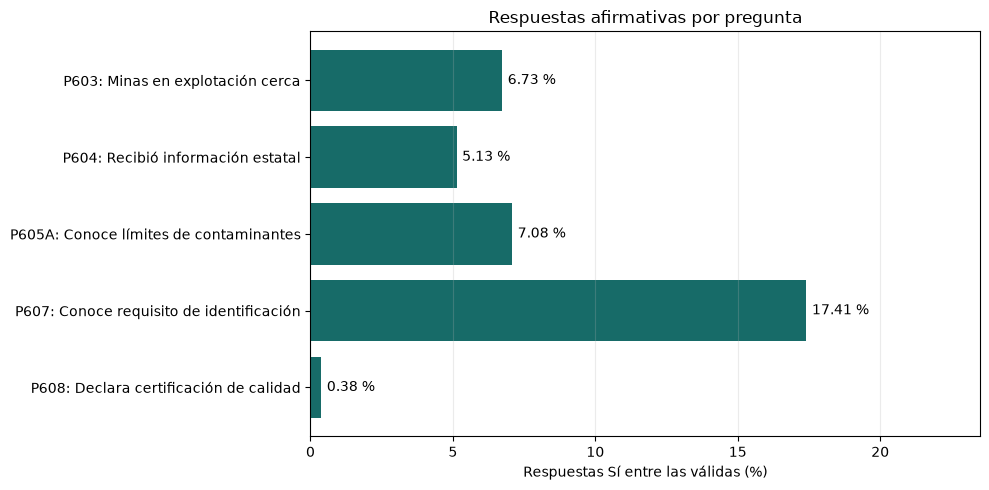

In [65]:
etiquetas_perfil = [
    "P603: Minas en explotación cerca",
    "P604: Recibió información estatal",
    "P605A: Conoce límites de contaminantes",
    "P607: Conoce requisito de identificación",
    "P608: Declara certificación de calidad",
]

# Gráfico de respuestas afirmativas
plt.figure(figsize=(10, 5))

barras = plt.barh(
    etiquetas_perfil,
    resumen_inocuidad["porcentaje_si"],
    color="#176B68"
)

# Mostrar porcentajes sobre las barras
plt.bar_label(barras, fmt="%.2f %%", padding=4)

plt.gca().invert_yaxis()
plt.margins(x=0.35)

plt.title("Respuestas afirmativas por pregunta")
plt.xlabel("Respuestas Sí entre las válidas (%)")

plt.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

**Lectura del perfil.** En `P607`, 6.476 de 37.202 UA elegibles (17,41 %) declararon conocer el requisito de identificación. En `P608`, 147 de 38.449 (0,38 %) declararon contar con certificación de calidad. Las barras representan preguntas de naturaleza distinta, con una base particular para `P607`.

### 7.2. P604: Información estatal por región natural

**Pregunta.** ¿Qué proporción de UA declaró que una entidad del Estado le informó sobre contaminación de alimentos en Costa, Sierra y Selva?

Calculamos las respuestas `Sí` entre las respuestas válidas de `P604` en cada región natural (`REGION`).

In [29]:
# Registros con región natural y respuesta válida
datos_region = df_analisis[
    df_analisis["REGION"].isin([1, 2, 3]) &
    df_analisis["P604"].isin([1, 2])
].copy()

print("Registros incluidos:", len(datos_region))
print("Registros no incluidos:", len(df_analisis) - len(datos_region))

Registros incluidos: 38449
Registros no incluidos: 0


In [30]:
# Frecuencias de información estatal por región
tabla_region = pd.crosstab(datos_region["REGION"], datos_region["P604"])

# Organizar regiones y respuestas
tabla_region = tabla_region.reindex(index=[1, 2, 3], columns=[1, 2], fill_value=0)
tabla_region.index = ["Costa", "Sierra", "Selva"]
tabla_region.columns = ["Sí", "No"]

display(tabla_region)

,Sí,No
Costa,549,8250
Sierra,1039,21399
Selva,384,6828


In [31]:
# Total de respuestas válidas por región
tabla_region["Total válido"] = tabla_region["Sí"] + tabla_region["No"]

# Porcentaje de respuestas Sí
tabla_region["Porcentaje Sí"] = (
    tabla_region["Sí"] / tabla_region["Total válido"].replace(0, float("nan")) * 100
).round(2)

display(tabla_region)

,Sí,No,Total válido,Porcentaje Sí
Costa,549,8250,8799,6.24
Sierra,1039,21399,22438,4.63
Selva,384,6828,7212,5.32


In [32]:
# Comprobar los totales
print("Registros incluidos:", len(datos_region))
print("Respuestas contabilizadas:", tabla_region["Total válido"].sum())
print("Totales coinciden:", len(datos_region) == tabla_region["Total válido"].sum())

# Comprobar los porcentajes
print("Porcentajes válidos:", tabla_region["Porcentaje Sí"].dropna().between(0, 100).all())

# Comprobar los códigos de región
print("Regiones encontradas:", sorted(datos_region["REGION"].dropna().unique().tolist()))

Registros incluidos: 38449
Respuestas contabilizadas: 38449
Totales coinciden: True
Porcentajes válidos: True
Regiones encontradas: [1, 2, 3]


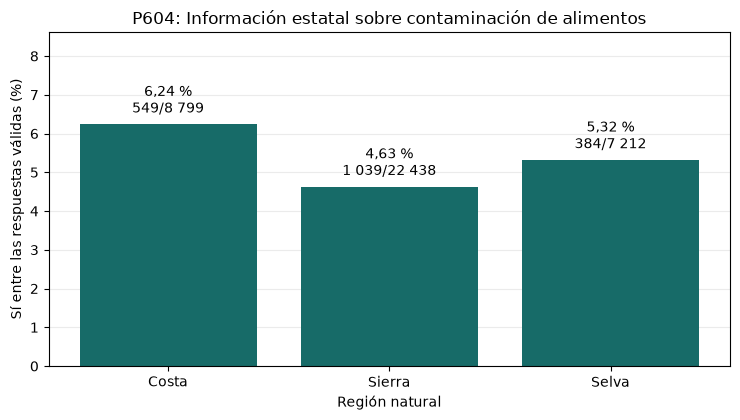

In [67]:
fig, ax = plt.subplots(figsize=(7.5, 4.3))
barras = ax.bar(tabla_region.index, tabla_region["Porcentaje Sí"], color="#176B68")
ax.bar_label(barras, labels=[
    f"{pct:.2f} %\n{si:,}/{n:,}".replace(",", " ").replace(".", ",")
    for pct, si, n in zip(tabla_region["Porcentaje Sí"],
                          tabla_region["Sí"], tabla_region["Total válido"])
], padding=5)
ax.margins(y=0.38)
ax.set(title="P604: Información estatal sobre contaminación de alimentos",
       xlabel="Región natural", ylabel="Sí entre las respuestas válidas (%)")
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

Costa registró la mayor proporción de respuestas afirmativas (549 de 8.799, 6,24 %) y Sierra el mayor conteo de afirmativas (1.039 de 22.438, 4,63 %). Selva registró 384 de 7.212 (5,32 %).

### 7.3. P604: Información estatal por departamento

**Pregunta.** ¿En qué departamentos de la base analizada fue más frecuente declarar que una entidad estatal informó sobre contaminación de alimentos?

El porcentaje usa las respuestas válidas de `P604` de cada departamento identificado en `NOMBREDD`. La agrupación por departamento parte directamente de la base filtrada.

In [68]:
# Frecuencias de información estatal por departamento
p604_departamento = df_analisis.loc[df_analisis["P604"].isin([1, 2])]
tabla_departamento = pd.crosstab(p604_departamento["NOMBREDD"], p604_departamento["P604"])
tabla_departamento = tabla_departamento.reindex(columns=[1, 2], fill_value=0)
tabla_departamento.columns = ["Sí", "No"]

# Orden de mayor a menor frecuencia de respuestas Sí
tabla_departamento = tabla_departamento.sort_values("Sí", ascending=False)

display(tabla_departamento)

,Sí,No
NOMBREDD,,
AYACUCHO,173,2819
TACNA,155,1003
APURIMAC,128,1653
CAJAMARCA,118,2690
LIMA,115,2220
PUNO,114,2197
JUNIN,106,1597
UCAYALI,96,731
ANCASH,93,2930


In [35]:
# Total de respuestas válidas por departamento
tabla_departamento["Total válido"] = tabla_departamento["Sí"] + tabla_departamento["No"]

# Porcentaje de respuestas Sí
tabla_departamento["Porcentaje Sí"] = (
    tabla_departamento["Sí"] / tabla_departamento["Total válido"] * 100
).round(2)

# Ordenar por porcentaje
tabla_departamento = tabla_departamento.sort_values("Porcentaje Sí", ascending=False)

display(tabla_departamento)

,Sí,No,Total válido,Porcentaje Sí
NOMBREDD,,,,
TACNA,155,1003,1158,13.39
UCAYALI,96,731,827,11.61
LAMBAYEQUE,82,701,783,10.47
ICA,81,860,941,8.61
APURIMAC,128,1653,1781,7.19
SAN MARTIN,86,1203,1289,6.67
JUNIN,106,1597,1703,6.22
HUANCAVELICA,77,1200,1277,6.03
MOQUEGUA,60,957,1017,5.90


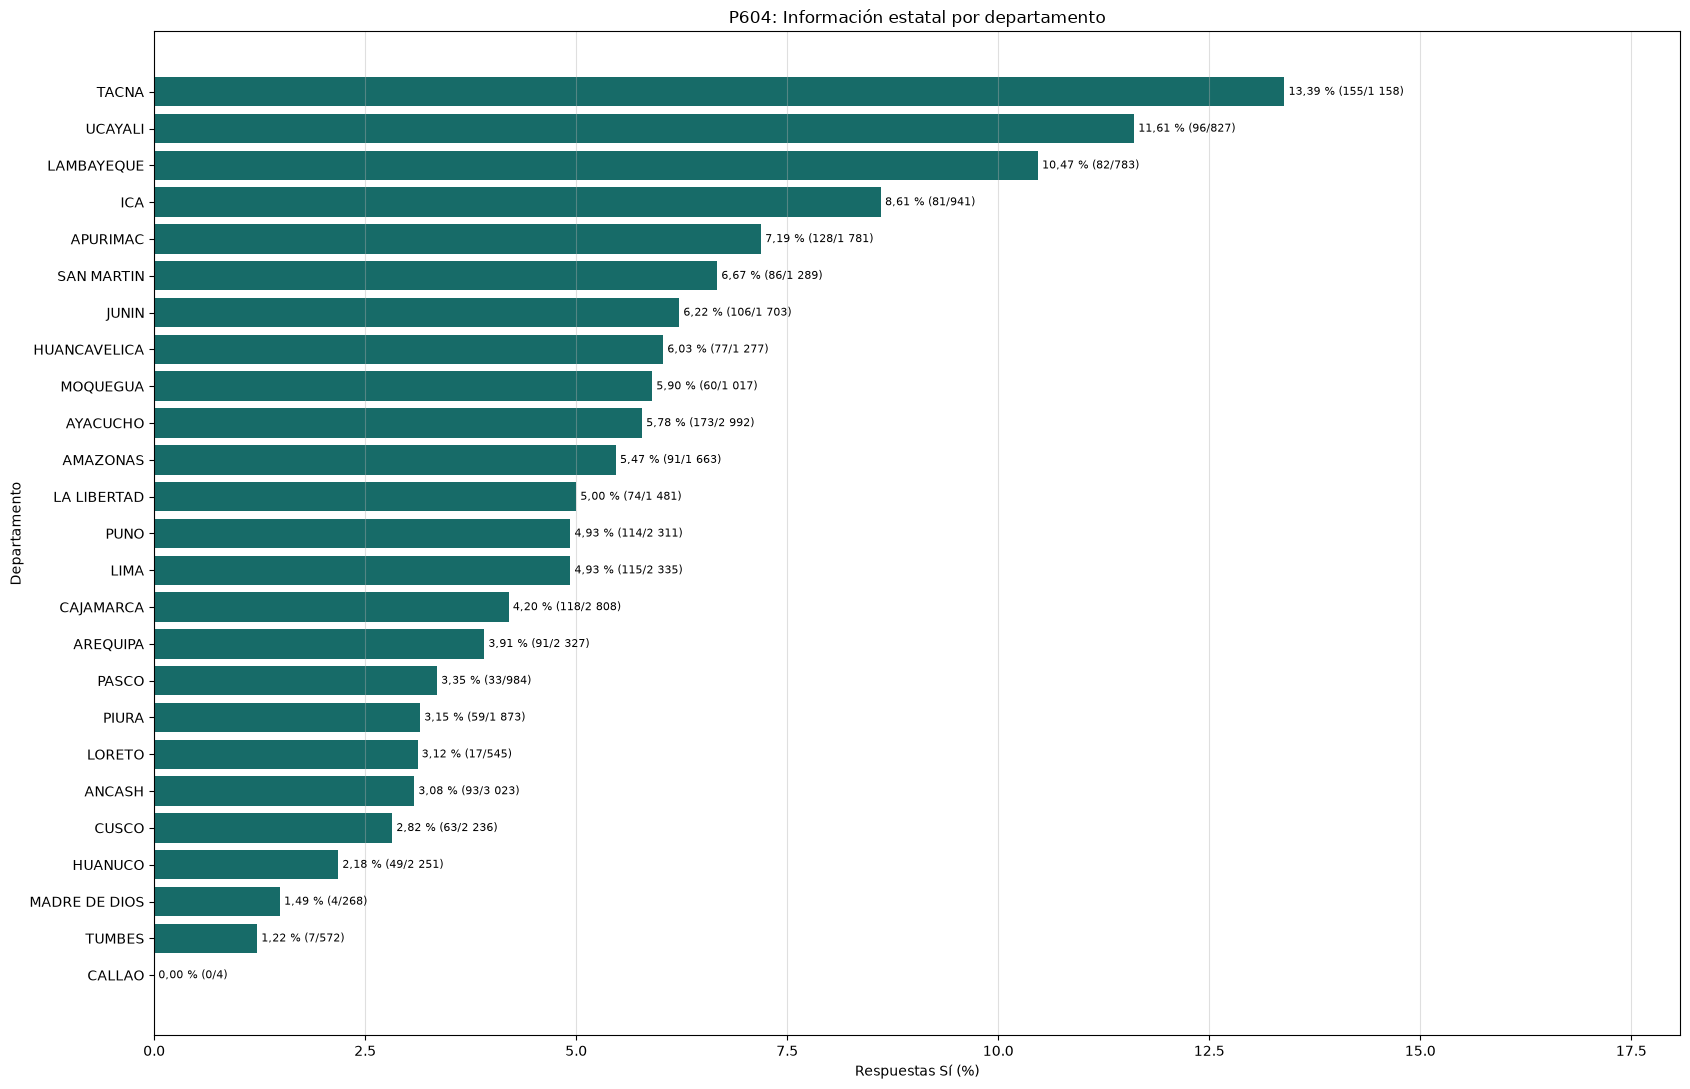

In [82]:
# Porcentaje de información estatal por departamento
tabla_grafico = tabla_departamento.sort_values("Porcentaje Sí")

# Etiquetas con porcentaje y cantidades
etiquetas = []

for departamento in tabla_grafico.index:
    porcentaje = tabla_grafico.loc[departamento, "Porcentaje Sí"]
    si = tabla_grafico.loc[departamento, "Sí"]
    total = tabla_grafico.loc[departamento, "Total válido"]

    etiqueta = f"{porcentaje:.2f} % ({si:,}/{total:,})"
    etiquetas.append(etiqueta.replace(",", " ").replace(".", ","))

# Gráfico
plt.figure(figsize=(17, 11))

barras = plt.barh(tabla_grafico.index, tabla_grafico["Porcentaje Sí"], color="#176B68")
plt.bar_label(barras, labels=etiquetas, padding=3, fontsize=8)

plt.margins(x=0.35)
plt.title("P604: Información estatal por departamento")
plt.xlabel("Respuestas Sí (%)")
plt.ylabel("Departamento")

plt.grid(axis="x", alpha=0.4)
plt.tight_layout()
plt.show()

Tacna tuvo el porcentaje más alto observado (155 de 1.158, 13,39 %). Callao registró 0 de 4 respuestas afirmativas. Una base de cuatro UA ofrece poca información para comparar. El ranking es descriptivo y la tabla muestra el tamaño de cada grupo.

### 7.4. P604 × P605A: Información recibida y conocimiento declarado

**Pregunta.** ¿Cómo difiere el conocimiento declarado de los límites máximos permisibles de contaminantes según se haya recibido información estatal sobre contaminación de alimentos?

Entre las UA con respuesta válida en ambas variables, agrupamos por `P604` y dividimos el número de respuestas `Sí` a `P605A` entre el total válido de cada grupo.

In [37]:
# Registros con respuestas válidas en ambas preguntas
datos_conocimiento = df_analisis[
    df_analisis["P604"].isin([1, 2]) &
    df_analisis["P605A"].isin([1, 2])
].copy()

print("Registros incluidos:", len(datos_conocimiento))
print("Registros no incluidos:", len(df_analisis) - len(datos_conocimiento))

Registros incluidos: 38449
Registros no incluidos: 0


In [38]:
# Frecuencias de conocimiento según información recibida
tabla_conocimiento = pd.crosstab(datos_conocimiento["P604"], datos_conocimiento["P605A"])

# Organizar las respuestas
tabla_conocimiento = tabla_conocimiento.reindex(index=[1, 2], columns=[1, 2], fill_value=0)
tabla_conocimiento.index = ["Recibió información", "No recibió información"]
tabla_conocimiento.columns = ["Conoce límites", "No conoce límites"]

display(tabla_conocimiento)

,Conoce límites,No conoce límites
Recibió información,610,1362
No recibió información,2114,34363


In [39]:
# Total de respuestas válidas por grupo
tabla_conocimiento["Total válido"] = tabla_conocimiento["Conoce límites"] + tabla_conocimiento["No conoce límites"]

# Porcentaje de respuestas Sí a P605A
tabla_conocimiento["Porcentaje Sí"] = (
    tabla_conocimiento["Conoce límites"] / tabla_conocimiento["Total válido"].replace(0, float("nan")) * 100
).round(2)

display(tabla_conocimiento)

,Conoce límites,No conoce límites,Total válido,Porcentaje Sí
Recibió información,610,1362,1972,30.93
No recibió información,2114,34363,36477,5.80


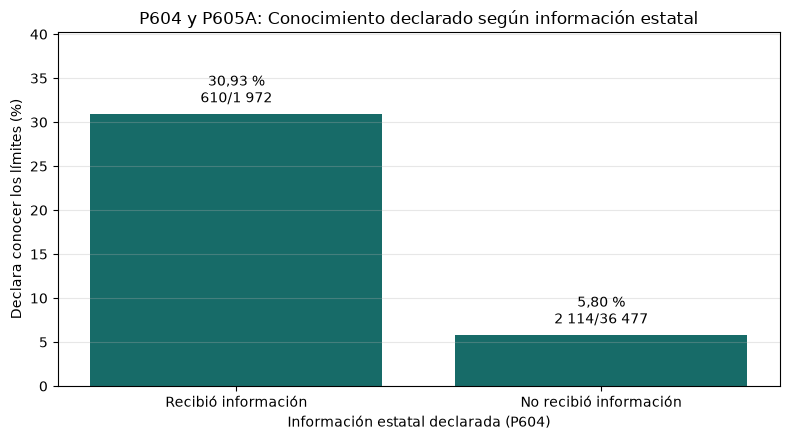

In [85]:
# Porcentaje de conocimiento según información estatal
plt.figure(figsize=(8, 4.5))
barras = plt.bar(tabla_conocimiento.index, tabla_conocimiento["Porcentaje Sí"], color="#176B68")

# Etiquetas con porcentajes y cantidades
etiquetas = []

for grupo in tabla_conocimiento.index:
    porcentaje = tabla_conocimiento.loc[grupo, "Porcentaje Sí"]
    si = tabla_conocimiento.loc[grupo, "Conoce límites"]
    total = tabla_conocimiento.loc[grupo, "Total válido"]

    etiqueta = f"{porcentaje:.2f} %\n{si:,}/{total:,}"
    etiquetas.append(etiqueta.replace(",", " ").replace(".", ","))

plt.bar_label(barras, labels=etiquetas, padding=5)

plt.margins(y=0.3)
plt.title("P604 y P605A: Conocimiento declarado según información estatal")
plt.xlabel("Información estatal declarada (P604)")
plt.ylabel("Declara conocer los límites (%)")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

**Lectura del cruce.** Declararon conocer los límites 610 de 1.972 UA que recibieron información (30,93 %) y 2.114 de 36.477 que no la recibieron (5,80 %). La diferencia observada es de **25,13 puntos porcentuales**. La encuesta muestra una diferencia entre grupos. Por sí sola no permite saber si la información explica esa diferencia.

### 7.5. P609: Modalidad de certificación de calidad

**Pregunta.** Entre quienes declararon contar con certificación (`P608 = 1`), ¿en qué modalidad se otorgó?

El filtro por nombre de departamento excluyó 488 registros con respuesta «Sí» en `P608`. Los 147 afirmativos conservados tienen una respuesta válida en `P609`: 1, como productor/a, o 2, como asociación, cooperativa o comité. El denominador de ambos porcentajes es 147. Los 488 afirmativos excluidos tienen `P609` vacío y su modalidad queda indeterminada en este archivo.

In [41]:
# Registros que declaran certificación
datos_certificacion = df_analisis[df_analisis["P608"] == 1].copy()

print("Registros con certificación:", len(datos_certificacion))
print("\nRespuestas de P609:")
print(datos_certificacion["P609"].value_counts(dropna=False))

Registros con certificación: 147

Respuestas de P609:
P609
2.0    80
1.0    67
Name: count, dtype: int64


In [42]:
# Respuestas válidas de modalidad
modalidades = datos_certificacion[datos_certificacion["P609"].isin([1, 2])]

# Frecuencias por modalidad
tabla_certificacion = modalidades["P609"].value_counts().reindex([1, 2], fill_value=0).to_frame("Frecuencia")
tabla_certificacion.index = ["1: Productor/a", "2: Asociación, cooperativa o comité"]

# Porcentaje de cada modalidad
tabla_certificacion["Porcentaje"] = (
    tabla_certificacion["Frecuencia"] / len(modalidades) * 100
).round(2)

display(tabla_certificacion)

,Frecuencia,Porcentaje
1: Productor/a,67,45.58
"2: Asociación, cooperativa o comité",80,54.42


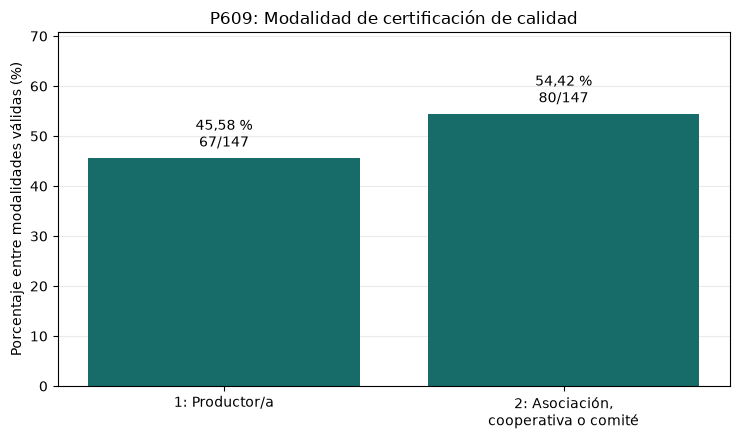

In [43]:
fig, ax = plt.subplots(figsize=(7.5, 4.5))
barras = ax.bar(["1: Productor/a", "2: Asociación,\ncooperativa o comité"],
                tabla_certificacion["Porcentaje"], color="#176B68")
ax.bar_label(barras, labels=[
    f"{pct:.2f} %\n{frecuencia}/{len(modalidades)}".replace(".", ",")
    for pct, frecuencia in zip(tabla_certificacion["Porcentaje"], tabla_certificacion["Frecuencia"])
], padding=5)
ax.margins(y=0.3)
ax.set(title="P609: Modalidad de certificación de calidad",
       ylabel="Porcentaje entre modalidades válidas (%)")
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

**Lectura de certificación.** La modalidad como asociación, cooperativa o comité fue más frecuente entre las 147 respuestas válidas (80 de 147, 54,42 %) que la modalidad como productor/a (67 de 147, 45,58 %). La distribución describe a los afirmativos conservados con modalidad registrada.

### 7.6. P601: Manejo de residuos agrícolas

**Pregunta.** ¿Qué prácticas de manejo de los residuos de cultivos declaran las unidades agropecuarias (UA) productoras agrícolas de la base analizada?

**Selección y alcance.** `P601_1` a `P601_6` distinguen usos y formas de disposición de residuos. Se analiza la base con departamento identificado. `P601_7 = 1` identifica «No es productor/a agrícola» y queda fuera de la base elegible. Se incluyen las filas con `P601_7 = 0` y se contabiliza por separado cualquier valor indeterminado.

**Lectura de las respuestas múltiples.** En estos bloques, 1 indica una opción marcada y 0 una opción sin marcar. Como criterio de análisis, una respuesta válida exige códigos 0/1 en las opciones consideradas y al menos una marca. El numerador es el número de UA válidas que marcó cada opción. El denominador es el total de UA con respuesta válida al bloque. Una misma UA puede marcar varias opciones, así que los porcentajes pueden sumar más de 100 %.

UA elegibles: 38373 | Válidas: 38373 | Elegibles sin respuesta válida: 0
No aplica: 76 | Aplicabilidad indeterminada: 0
UA válidas con más de una opción: 16556
No aplicables con alguna opción marcada: 0


,Opción,UA que marcaron,UA válidas,Porcentaje (%)
Código,,,,
P601_1,Quema o incinera,6648,38373,17.32
P601_2,Usa como alimento para animales de crianza,9567,38373,24.93
P601_3,Bota,1344,38373,3.50
P601_4,Usa como abono,11453,38373,29.85
P601_5,Deja en el campo,28985,38373,75.53
P601_6,Otro,502,38373,1.31


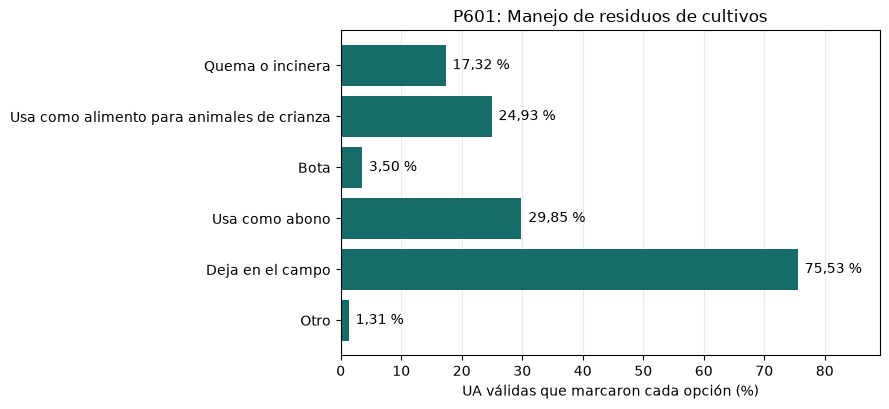

In [44]:
opciones_p601 = {
    "P601_1": "Quema o incinera",
    "P601_2": "Usa como alimento para animales de crianza",
    "P601_3": "Bota",
    "P601_4": "Usa como abono",
    "P601_5": "Deja en el campo",
    "P601_6": "Otro",
}
elegibles_p601 = df_analisis["P601_7"].eq(0)
no_aplica_p601 = df_analisis["P601_7"].eq(1)
respuestas_p601 = df_analisis.loc[elegibles_p601, list(opciones_p601)]
validas_p601 = respuestas_p601.isin([0, 1]).all(axis=1) & respuestas_p601.eq(1).any(axis=1)
marcas_p601 = respuestas_p601.loc[validas_p601].eq(1)
n_p601 = len(marcas_p601)

tabla_p601 = pd.DataFrame({
    "Opción": pd.Series(opciones_p601),
    "UA que marcaron": marcas_p601.sum(),
    "UA válidas": n_p601,
}).rename_axis("Código")
tabla_p601["Porcentaje (%)"] = (
    tabla_p601["UA que marcaron"] / n_p601 * 100
).round(2)

print("UA elegibles:", len(respuestas_p601),
      "| Válidas:", n_p601,
      "| Elegibles sin respuesta válida:", len(respuestas_p601) - n_p601)
print("No aplica:", no_aplica_p601.sum(),
      "| Aplicabilidad indeterminada:", (~(elegibles_p601 | no_aplica_p601)).sum())
print("UA válidas con más de una opción:", marcas_p601.sum(axis=1).gt(1).sum())
print("No aplicables con alguna opción marcada:",
      df_analisis.loc[no_aplica_p601, list(opciones_p601)].eq(1).any(axis=1).sum())
display(tabla_p601)

fig, ax = plt.subplots(figsize=(9, 4.2))
barras = ax.barh(tabla_p601["Opción"], tabla_p601["Porcentaje (%)"], color="#176B68")
ax.invert_yaxis()
ax.bar_label(barras, labels=[
    f"{porcentaje:.2f} %".replace(".", ",")
    for porcentaje in tabla_p601["Porcentaje (%)"]
], padding=5)
ax.margins(x=0.18)
ax.set(title="P601: Manejo de residuos de cultivos", xlabel="UA válidas que marcaron cada opción (%)")
ax.set_axisbelow(True)
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()

**Interpretación.** De las 38.373 UA con respuesta válida, 28.985 (75,53 %) declararon dejar residuos en el campo y 11.453 (29,85 %) usarlos como abono. Los porcentajes expresan la frecuencia con que se declaró cada práctica. El módulo no registra en este bloque la cantidad de residuos manejada por cada vía.

**Auditoría.** Se excluyeron 76 filas con `P601_7 = 1`, sin marcas en las seis opciones de manejo. Las 38.373 elegibles aportaron una respuesta válida y 16.556 marcaron más de una opción. Estas cifras cuentan unidades que declararon cada práctica sobre los residuos de cultivos.

### 7.7. P602: Manejo de residuos pecuarios

**Pregunta.** ¿Qué prácticas de manejo de los residuos de animales de crianza declaran las UA a las que les aplica el bloque pecuario?

**Selección y alcance.** Las opciones `P602_1` a `P602_7` distinguen prácticas sobre residuos pecuarios. La población elegible cumple `P602_8 = 0` y `P602_9 = 0`. Se excluyen las filas que marcaron «Es solo productor apícola» (`P602_8 = 1`) o «No es productor pecuario» (`P602_9 = 1`). Se aplica el criterio de respuesta múltiple de la sección 7.6.

In [45]:
opciones_p602 = {
    "P602_1": "Quema o incinera",
    "P602_2": "Entierra",
    "P602_3": "Bota",
    "P602_4": "Usa como abono",
    "P602_5": "Usa como combustible",
    "P602_6": "Deja en el campo",
    "P602_7": "Otro",
}
elegibles_p602 = df_analisis["P602_8"].eq(0) & df_analisis["P602_9"].eq(0)
no_aplica_p602 = df_analisis["P602_8"].eq(1) | df_analisis["P602_9"].eq(1)
respuestas_p602 = df_analisis.loc[elegibles_p602, list(opciones_p602)]
validas_p602 = respuestas_p602.isin([0, 1]).all(axis=1) & respuestas_p602.eq(1).any(axis=1)
marcas_p602 = respuestas_p602.loc[validas_p602].eq(1)
n_p602 = len(marcas_p602)

tabla_p602 = pd.DataFrame({
    "Opción": pd.Series(opciones_p602),
    "UA que marcaron": marcas_p602.sum(),
    "UA válidas": n_p602,
}).rename_axis("Código")
tabla_p602["Porcentaje (%)"] = (
    tabla_p602["UA que marcaron"] / n_p602 * 100
).round(2)

print("UA elegibles:", len(respuestas_p602),
      "| Válidas:", n_p602,
      "| Elegibles sin respuesta válida:", len(respuestas_p602) - n_p602)
print("No aplica:", no_aplica_p602.sum(),
      "| Aplicabilidad indeterminada:", (~(elegibles_p602 | no_aplica_p602)).sum())
print("UA válidas con más de una opción:", marcas_p602.sum(axis=1).gt(1).sum())
print("No aplicables con alguna opción marcada:",
      df_analisis.loc[no_aplica_p602, list(opciones_p602)].eq(1).any(axis=1).sum())
display(tabla_p602)

print("Marcó solo productor apícola (P602_8):", df_analisis["P602_8"].eq(1).sum())
print("Marcó no productor pecuario (P602_9):", df_analisis["P602_9"].eq(1).sum())
print("Marcó ambos motivos:", (df_analisis["P602_8"].eq(1) & df_analisis["P602_9"].eq(1)).sum())

UA elegibles: 27144 | Válidas: 27144 | Elegibles sin respuesta válida: 0
No aplica: 11305 | Aplicabilidad indeterminada: 0
UA válidas con más de una opción: 9615
No aplicables con alguna opción marcada: 0


,Opción,UA que marcaron,UA válidas,Porcentaje (%)
Código,,,,
P602_1,Quema o incinera,356,27144,1.31
P602_2,Entierra,627,27144,2.31
P602_3,Bota,2898,27144,10.68
P602_4,Usa como abono,16768,27144,61.77
P602_5,Usa como combustible,2182,27144,8.04
P602_6,Deja en el campo,15132,27144,55.75
P602_7,Otro,76,27144,0.28


Marcó solo productor apícola (P602_8): 37
Marcó no productor pecuario (P602_9): 11268
Marcó ambos motivos: 0


**Interpretación.** Entre las 27.144 UA con respuesta válida, 16.768 (61,77 %) declararon usar estos residuos como abono y 15.132 (55,75 %) dejarlos en el campo. Una UA pudo declarar ambas prácticas. El porcentaje se refiere a UA que declararon cada manejo, sin información sobre el volumen manejado.

**Auditoría.** Se excluyeron 37 filas de productores exclusivamente apícolas y 11.268 de quienes señalaron que no eran productores pecuarios. Ninguna unidad excluida marcó ambas opciones ni declaró una práctica de manejo en este bloque. Las 27.144 elegibles aportaron una respuesta válida. Este bloque analiza residuos animales y su base elegible difiere de la del bloque agrícola.

### 7.8. P605: Entidades que informaron sobre contaminación de alimentos

**Pregunta.** Entre las UA que declararon recibir información estatal sobre contaminación de alimentos, ¿qué entidades identificaron como fuentes?

**Selección y alcance.** `P604` registra si se recibió información estatal. `P605_1` a `P605_6` permiten identificar qué entidades informaron. El bloque aplica a las UA con `P604 = 1`. Las que respondieron `P604 = 2` quedan fuera del denominador. Se aplica el criterio de respuesta múltiple de la sección 7.6.

In [46]:
opciones_p605 = {
    "P605_1": "Servicio Nacional de Sanidad Agraria (SENASA)",
    "P605_2": "Ministerio de Salud",
    "P605_3": "Ministerio de Desarrollo Agrario y Riego",
    "P605_4": "Gobierno Regional",
    "P605_5": "Gobierno Local/Municipal",
    "P605_6": "Otro",
}
elegibles_p605 = df_analisis["P604"].eq(1)
no_aplica_p605 = df_analisis["P604"].eq(2)
respuestas_p605 = df_analisis.loc[elegibles_p605, list(opciones_p605)]
validas_p605 = respuestas_p605.isin([0, 1]).all(axis=1) & respuestas_p605.eq(1).any(axis=1)
marcas_p605 = respuestas_p605.loc[validas_p605].eq(1)
n_p605 = len(marcas_p605)

tabla_p605 = pd.DataFrame({
    "Opción": pd.Series(opciones_p605),
    "UA que marcaron": marcas_p605.sum(),
    "UA válidas": n_p605,
}).rename_axis("Código")
tabla_p605["Porcentaje (%)"] = (
    tabla_p605["UA que marcaron"] / n_p605 * 100
).round(2)

print("UA elegibles:", len(respuestas_p605),
      "| Válidas:", n_p605,
      "| Elegibles sin respuesta válida:", len(respuestas_p605) - n_p605)
print("No aplica:", no_aplica_p605.sum(),
      "| Aplicabilidad indeterminada:", (~(elegibles_p605 | no_aplica_p605)).sum())
print("UA válidas con más de una opción:", marcas_p605.sum(axis=1).gt(1).sum())
print("No aplicables con alguna opción marcada:",
      df_analisis.loc[no_aplica_p605, list(opciones_p605)].eq(1).any(axis=1).sum())
display(tabla_p605)

print("UA con P604 = 2 y las seis opciones vacías:",
      df_analisis.loc[no_aplica_p605, list(opciones_p605)].isna().all(axis=1).sum())

UA elegibles: 1972 | Válidas: 1972 | Elegibles sin respuesta válida: 0
No aplica: 36477 | Aplicabilidad indeterminada: 0
UA válidas con más de una opción: 170
No aplicables con alguna opción marcada: 0


,Opción,UA que marcaron,UA válidas,Porcentaje (%)
Código,,,,
P605_1,Servicio Nacional de Sanidad Agraria (SENASA),731,1972,37.07
P605_2,Ministerio de Salud,890,1972,45.13
P605_3,Ministerio de Desarrollo Agrario y Riego,159,1972,8.06
P605_4,Gobierno Regional,87,1972,4.41
P605_5,Gobierno Local/Municipal,244,1972,12.37
P605_6,Otro,55,1972,2.79


UA con P604 = 2 y las seis opciones vacías: 36477


**Interpretación.** Entre las 1.972 UA con respuesta válida, 890 (45,13 %) mencionaron al Ministerio de Salud y 731 (37,07 %) al SENASA. Esas fueron las dos entidades más mencionadas dentro del grupo que declaró haber recibido información. El bloque no mide la cobertura institucional sobre todas las UA ni la calidad de la información.

**Auditoría.** Las 36.477 UA con `P604 = 2` tienen vacías las seis opciones de `P605`. Las 1.972 elegibles aportaron una respuesta válida y 170 marcaron más de una entidad. Este bloque responde **quién informó**. Las secciones 7.2 y 7.3 describen **dónde se declaró haber recibido información**, y la 7.4 cruza esa recepción con el conocimiento declarado.

### 7.9. P606: Conservación y venta inmediata de productos primarios

**Pregunta.** ¿Qué lugares de conservación y qué otras opciones de manejo declaran las UA que producen alimentos de consumo humano en la base analizada?

**Selección y alcance.** El diccionario limita la pregunta a productos primarios. Se consideran elegibles las filas con `P606_7 = 0`. La opción `P606_7 = 1` significa «No produce alimentos de consumo humano» y queda fuera del denominador. `P606_1` a `P606_4` describen lugares o condiciones, `P606_5` significa «Otro» y `P606_6` corresponde a venta inmediata. La venta inmediata se presenta aparte de los lugares dentro de la misma tabla y la figura. Se aplica el criterio de respuesta múltiple de la sección 7.6.

UA elegibles: 37202 | Válidas: 37202 | Elegibles sin respuesta válida: 0
No aplica: 1247 | Aplicabilidad indeterminada: 0
UA válidas con más de una opción: 13715
No aplicables con alguna opción marcada: 0


,Opción,UA que marcaron,UA válidas,Porcentaje (%)
Código,,,,
P606_1,En un lugar refrigerado,1258,37202,3.38
P606_2,A la intemperie,4198,37202,11.28
P606_3,En cuarto seguro y ventilado,19415,37202,52.19
P606_4,En cuarto no adecuado,14510,37202,39.00
P606_5,Otro,452,37202,1.21
P606_6,Venta inmediata,12578,37202,33.81


Venta inmediata junto con alguna otra opción: 10998


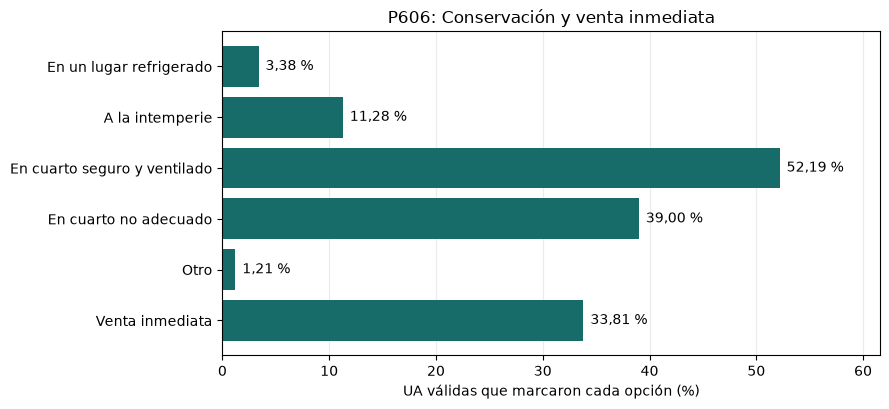

In [47]:
opciones_p606 = {
    "P606_1": "En un lugar refrigerado",
    "P606_2": "A la intemperie",
    "P606_3": "En cuarto seguro y ventilado",
    "P606_4": "En cuarto no adecuado",
    "P606_5": "Otro",
    "P606_6": "Venta inmediata",
}
elegibles_p606 = df_analisis["P606_7"].eq(0)
no_aplica_p606 = df_analisis["P606_7"].eq(1)
respuestas_p606 = df_analisis.loc[elegibles_p606, list(opciones_p606)]
validas_p606 = respuestas_p606.isin([0, 1]).all(axis=1) & respuestas_p606.eq(1).any(axis=1)
marcas_p606 = respuestas_p606.loc[validas_p606].eq(1)
n_p606 = len(marcas_p606)

tabla_p606 = pd.DataFrame({
    "Opción": pd.Series(opciones_p606),
    "UA que marcaron": marcas_p606.sum(),
    "UA válidas": n_p606,
}).rename_axis("Código")
tabla_p606["Porcentaje (%)"] = (
    tabla_p606["UA que marcaron"] / n_p606 * 100
).round(2)

print("UA elegibles:", len(respuestas_p606),
      "| Válidas:", n_p606,
      "| Elegibles sin respuesta válida:", len(respuestas_p606) - n_p606)
print("No aplica:", no_aplica_p606.sum(),
      "| Aplicabilidad indeterminada:", (~(elegibles_p606 | no_aplica_p606)).sum())
print("UA válidas con más de una opción:", marcas_p606.sum(axis=1).gt(1).sum())
print("No aplicables con alguna opción marcada:",
      df_analisis.loc[no_aplica_p606, list(opciones_p606)].eq(1).any(axis=1).sum())
display(tabla_p606)

print("Venta inmediata junto con alguna otra opción:",
      (marcas_p606["P606_6"] & marcas_p606.drop(columns="P606_6").any(axis=1)).sum())

fig, ax = plt.subplots(figsize=(9, 4.2))
barras = ax.barh(tabla_p606["Opción"], tabla_p606["Porcentaje (%)"], color="#176B68")
ax.invert_yaxis()
ax.bar_label(barras, labels=[
    f"{porcentaje:.2f} %".replace(".", ",")
    for porcentaje in tabla_p606["Porcentaje (%)"]
], padding=5)
ax.margins(x=0.18)
ax.set(title="P606: Conservación y venta inmediata", xlabel="UA válidas que marcaron cada opción (%)")
ax.set_axisbelow(True)
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()

**Interpretación.** De las 37.202 UA con respuesta válida, 19.415 (52,19 %) declararon guardar productos en un cuarto seguro y ventilado y 14.510 (39,00 %) en un cuarto no adecuado. La venta inmediata fue declarada por 12.578 UA (33,81 %). De ellas, 10.998 también marcaron alguna opción de lugar u «Otro». Las categorías registran lo declarado por las UA, sin una verificación de las condiciones sanitarias.

**Auditoría.** Las 1.247 filas con `P606_7 = 1` carecen de marcas en las seis opciones. Las 37.202 elegibles aportaron una respuesta válida, incluidas las que solo declararon venta inmediata. El bloque describe conservación y venta. La pregunta `P607` comparte la condición de elegibilidad y mide conocimiento sobre identificación de productos.

### 7.10. P607: Requisito de identificación por región natural

**Pregunta.** ¿Cómo varía entre Costa, Sierra y Selva el conocimiento declarado del requisito de identificar los productos primarios destinados al consumo humano?

**Base del análisis.** `P607` pregunta si la UA sabe que los alimentos de consumo humano que produce deben estar identificados para su consumo. Se conservan las UA de la base con departamento a las que les aplica la pregunta (`P606_7 = 0`) y con respuesta válida en `P607` (1, «Sí»; 2, «No»). `P606_7 = 1` indica que la UA marcó «No produce alimentos de consumo humano». El denominador es el total válido dentro de cada región natural (`REGION`: 1, Costa; 2, Sierra; 3, Selva).

UA elegibles: 37202 | Respuestas válidas de P607: 37202 | Válidas sin código regional reconocido: 0
Base de la tabla coincide con las UA usadas: True


,Sí,No,Total válido,Sí (%)
Región natural,,,,
Costa,2153,6371,8524,25.26
Sierra,2884,18849,21733,13.27
Selva,1439,5506,6945,20.72


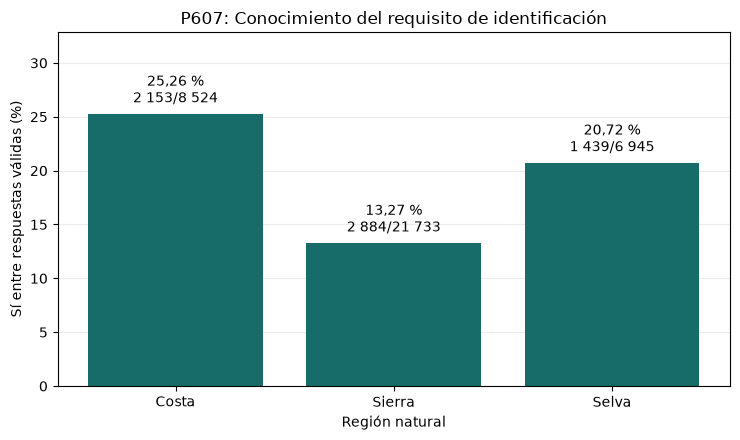

In [48]:
regiones_naturales = {1: "Costa", 2: "Sierra", 3: "Selva"}
validas_p607_region = elegibles_p607 & df_analisis["P607"].isin([1, 2])
datos_p607_region = df_analisis.loc[
    validas_p607_region & df_analisis["REGION"].isin(regiones_naturales)
]

tabla_p607_region = pd.crosstab(datos_p607_region["REGION"], datos_p607_region["P607"])
tabla_p607_region = tabla_p607_region.reindex(
    index=list(regiones_naturales), columns=[1, 2], fill_value=0
).rename(index=regiones_naturales, columns={1: "Sí", 2: "No"}).rename_axis(
    index="Región natural", columns=None
)
tabla_p607_region["Total válido"] = tabla_p607_region["Sí"] + tabla_p607_region["No"]
tabla_p607_region["Sí (%)"] = (
    tabla_p607_region["Sí"] / tabla_p607_region["Total válido"] * 100
).round(2)

print("UA elegibles:", elegibles_p607.sum(),
      "| Respuestas válidas de P607:", validas_p607_region.sum(),
      "| Válidas sin código regional reconocido:", validas_p607_region.sum() - len(datos_p607_region))
print("Base de la tabla coincide con las UA usadas:", tabla_p607_region["Total válido"].sum() == len(datos_p607_region))
display(tabla_p607_region)

fig, ax = plt.subplots(figsize=(7.5, 4.5))
barras = ax.bar(tabla_p607_region.index, tabla_p607_region["Sí (%)"], color="#176B68")
ax.bar_label(barras, labels=[
    f"{p:.2f} %\n{si:,}/{n:,}".replace(",", " ").replace(".", ",")
    for p, si, n in zip(tabla_p607_region["Sí (%)"],
                        tabla_p607_region["Sí"], tabla_p607_region["Total válido"])
], padding=5)
ax.margins(y=0.3)
ax.set(title="P607: Conocimiento del requisito de identificación",
       xlabel="Región natural", ylabel="Sí entre respuestas válidas (%)")
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

**Interpretación.** Declararon conocer el requisito 2.153 de 8.524 UA de Costa (25,26 %), 1.439 de 6.945 en Selva (20,72 %) y 2.884 de 21.733 en Sierra (13,27 %). Costa tuvo la mayor proporción observada y Sierra el mayor número de respuestas afirmativas. Los resultados se basan en lo que declaró cada unidad y la encuesta no identifica las causas de las diferencias.

**Auditoría.** Las 37.202 UA elegibles tuvieron respuesta válida y código regional reconocido. Los 6.476 «Sí» y los 30.726 «No» coinciden con el total de la sección 7.1. Este cruce agrega la comparación por región a la cifra general.

### 7.11. P610: Tipos de certificación declarados

**Pregunta.** ¿Qué tipos de certificación declaran las UA certificadas?

**Base del análisis.** `P608 = 1` significa que la UA declaró alguna certificación de calidad otorgada por una institución. Entre esas UA se analizan los nombres de certificación del diccionario (`P610_1` a `P610_6`). En cada opción, 1 significa «marcada» y 0 «sin marcar». Se usan los registros con códigos válidos en las seis opciones y al menos una marca. El denominador es el número de UA certificadas con respuesta válida al bloque. Una UA puede mencionar varios tipos.

In [49]:
opciones_p610 = {
    "P610_1": "Buenas prácticas agrícolas (Global Gap)",
    "P610_2": "Comercio justo (Fair trade)",
    "P610_3": "TNC (Tesco Natural Choice)",
    "P610_4": "Orgánica",
    "P610_5": "Buenas prácticas de manufacturas",
    "P610_6": "Otro",
}
columnas_p610 = list(opciones_p610)
respuestas_p610 = datos_certificacion[columnas_p610]
validas_p610 = respuestas_p610.isin([0, 1]).all(axis=1) & respuestas_p610.eq(1).any(axis=1)
marcas_p610 = respuestas_p610.loc[validas_p610].eq(1)
n_p610 = len(marcas_p610)

tabla_p610 = pd.DataFrame({
    "Tipo de certificación": pd.Series(opciones_p610),
    "UA que marcaron": marcas_p610.sum(),
    "UA válidas": n_p610,
}).rename_axis("Código")
tabla_p610["Porcentaje (%)"] = (tabla_p610["UA que marcaron"] / n_p610 * 100).round(2)

print("UA elegibles:", len(respuestas_p610), "| Válidas:", n_p610,
      "| Elegibles sin respuesta válida:", len(respuestas_p610) - n_p610)
print("UA válidas con más de un tipo:", marcas_p610.sum(axis=1).gt(1).sum())
print("Respuestas de P610 entre UA con P608 = 2:",
      df_analisis.loc[df_analisis["P608"].eq(2), columnas_p610].notna().any(axis=1).sum())
certificadas_fuera_p610 = df_inocuidad["NOMBREDD"].isna() & df_inocuidad["P608"].eq(1)
print("Certificadas excluidas por falta de departamento:", certificadas_fuera_p610.sum(),
      "| Con algún tipo marcado:",
      df_inocuidad.loc[certificadas_fuera_p610, columnas_p610].eq(1).any(axis=1).sum())
display(tabla_p610)

UA elegibles: 147 | Válidas: 147 | Elegibles sin respuesta válida: 0
UA válidas con más de un tipo: 12
Respuestas de P610 entre UA con P608 = 2: 0
Certificadas excluidas por falta de departamento: 488 | Con algún tipo marcado: 488


,Tipo de certificación,UA que marcaron,UA válidas,Porcentaje (%)
Código,,,,
P610_1,Buenas prácticas agrícolas (Global Gap),45,147,30.61
P610_2,Comercio justo (Fair trade),11,147,7.48
P610_3,TNC (Tesco Natural Choice),2,147,1.36
P610_4,Orgánica,102,147,69.39
P610_5,Buenas prácticas de manufacturas,2,147,1.36
P610_6,Otro,0,147,0.00


**Interpretación.** Entre las 147 UA certificadas con respuesta válida, 102 (69,39 %) declararon certificación orgánica y 45 (30,61 %) mencionaron Global Gap. Fueron los dos tipos más frecuentes en la base analizada. La distribución corresponde al grupo con departamento identificado.

**Auditoría.** Las 147 UA elegibles respondieron y 12 marcaron más de un tipo. Por eso la suma de porcentajes puede superar 100 %. Las 488 certificadas excluidas por falta de departamento sí marcaron algún tipo en `P610`. Los tipos de `P610` y las modalidades de otorgamiento de `P609` responden a preguntas distintas.

### 7.12. P608: Certificación declarada por región natural

**Pregunta.** ¿Cómo varía la proporción de UA que declara certificación de calidad entre Costa, Sierra y Selva?

**Base del análisis.** Se mantiene el filtro oficial de departamento. En este archivo, las UA que quedaron corresponden a personas naturales (`CODIGO = 1`). Para cada región natural se divide el número de UA con `P608 = 1` («Sí») entre las UA con respuesta «Sí» o «No» (1 o 2).

In [50]:
validas_p608_region = df_analisis["P608"].isin([1, 2])
datos_p608_region = df_analisis.loc[
    validas_p608_region & df_analisis["REGION"].isin(regiones_naturales)
]
tabla_p608_region = pd.crosstab(datos_p608_region["REGION"], datos_p608_region["P608"])
tabla_p608_region = tabla_p608_region.reindex(
    index=list(regiones_naturales), columns=[1, 2], fill_value=0
).rename(index=regiones_naturales, columns={1: "Sí", 2: "No"}).rename_axis(
    index="Región natural", columns=None
)
tabla_p608_region["Total válido"] = tabla_p608_region["Sí"] + tabla_p608_region["No"]
tabla_p608_region["Sí (%)"] = (
    tabla_p608_region["Sí"] / tabla_p608_region["Total válido"] * 100
).round(2)

print("UA conservadas:", len(df_analisis), "| Válidas en la tabla:", len(datos_p608_region),
      "| Válidas sin código regional reconocido:", validas_p608_region.sum() - len(datos_p608_region))
print("Afirmativas coinciden con P608 de la sección 7.1:",
      tabla_p608_region["Sí"].sum() == resumen_inocuidad.loc["P608", "si"])
display(tabla_p608_region)

UA conservadas: 38449 | Válidas en la tabla: 38449 | Válidas sin código regional reconocido: 0
Afirmativas coinciden con P608 de la sección 7.1: True


,Sí,No,Total válido,Sí (%)
Región natural,,,,
Costa,53,8746,8799,0.60
Sierra,10,22428,22438,0.04
Selva,84,7128,7212,1.16


**Interpretación.** En Selva declararon certificación 84 de 7.212 UA (1,16 %). En Costa fueron 53 de 8.799 (0,60 %) y en Sierra, 10 de 22.438 (0,04 %). El resultado de Sierra se apoya en solo diez respuestas afirmativas, aunque su base válida sea la mayor.

**Auditoría.** Los totales coinciden con las 38.449 respuestas válidas y las 147 afirmativas de la base filtrada. El filtro deja fuera a 488 UA certificadas sin departamento. Los porcentajes se calcularon directamente con las respuestas conservadas y se refieren a ese grupo. Este cruce estudia la frecuencia de certificación por región. El bloque anterior describe tipos dentro del grupo certificado.

### 7.13. P603: Cercanía declarada a minas por departamento

**Pregunta.** ¿Cómo varía por departamento la cercanía declarada de minas en explotación a los cultivos o animales de crianza de las UA?

**Base del análisis.** Se agrupa por el código de departamento (`CCDD`) y se muestra su nombre (`NOMBREDD`). Para cada departamento, el numerador es el número de «Sí» (1) en `P603` y el denominador son los «Sí» más los «No» (2). Se exige un código de departamento registrado y se comprueba que cada código se corresponda con un solo nombre y viceversa.

Departamentos con respuestas válidas: 25
Respuestas válidas sin código de departamento: 0
Afirmativas coinciden con P603 de la sección 7.1: True


,CCDD,NOMBREDD,Sí,No,Total válido,Sí (%)
0,18,MOQUEGUA,232,785,1017,22.81
1,04,AREQUIPA,520,1807,2327,22.35
2,17,MADRE DE DIOS,38,230,268,14.18
3,23,TACNA,144,1014,1158,12.44
4,11,ICA,92,849,941,9.78
5,08,CUSCO,211,2025,2236,9.44
6,02,ANCASH,254,2769,3023,8.40
7,06,CAJAMARCA,209,2599,2808,7.44
8,03,APURIMAC,121,1660,1781,6.79
9,15,LIMA,143,2192,2335,6.12


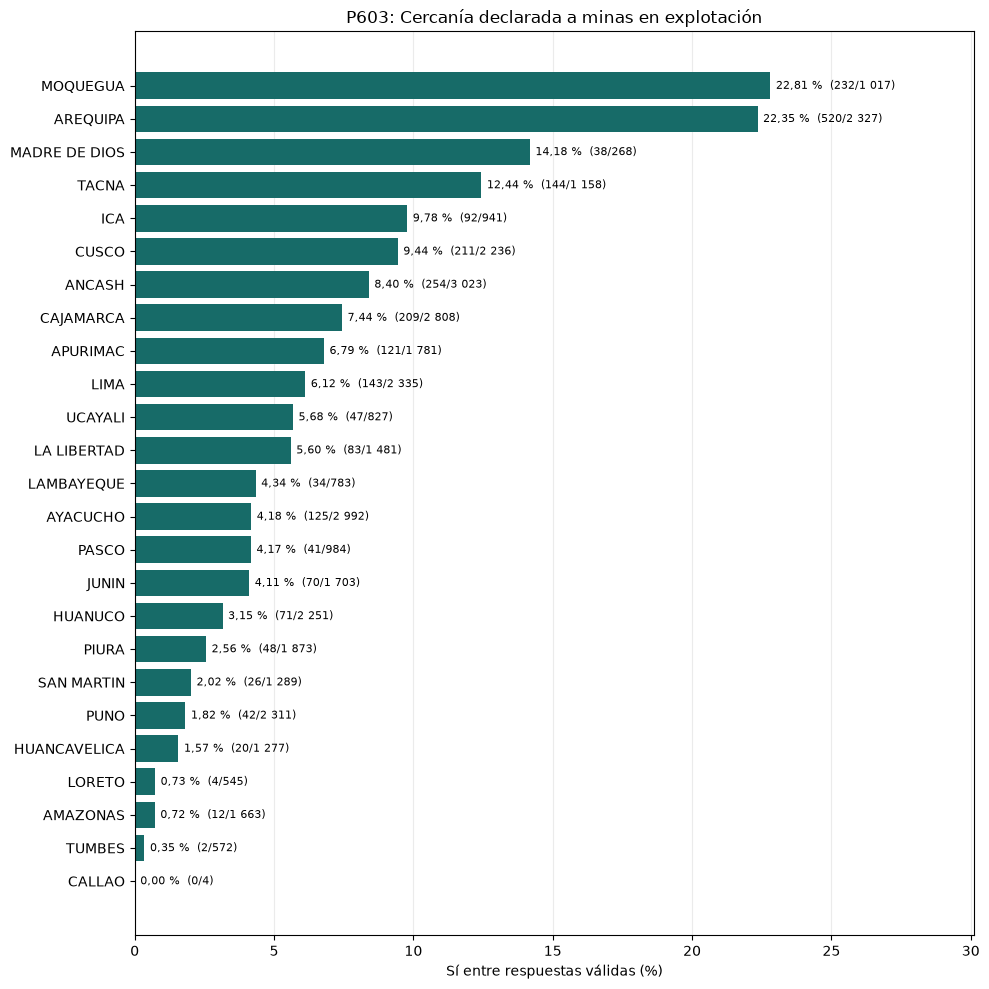

In [51]:
validas_p603 = df_analisis["P603"].isin([1, 2])
datos_p603_departamento = df_analisis.loc[
    validas_p603 & df_analisis["CCDD"].notna()
]
pares_departamento_p603 = datos_p603_departamento[["CCDD", "NOMBREDD"]].drop_duplicates()
assert pares_departamento_p603["CCDD"].is_unique and pares_departamento_p603["NOMBREDD"].is_unique

tabla_p603_departamento = pd.crosstab(
    [datos_p603_departamento["CCDD"], datos_p603_departamento["NOMBREDD"]],
    datos_p603_departamento["P603"],
).reindex(columns=[1, 2], fill_value=0).rename(columns={1: "Sí", 2: "No"}).rename_axis(columns=None)
tabla_p603_departamento["Total válido"] = tabla_p603_departamento["Sí"] + tabla_p603_departamento["No"]
tabla_p603_departamento["Sí (%)"] = (
    tabla_p603_departamento["Sí"] / tabla_p603_departamento["Total válido"] * 100
).round(2)
tabla_p603_departamento = tabla_p603_departamento.reset_index().sort_values("Sí (%)", ascending=False)
tabla_p603_departamento["CCDD"] = tabla_p603_departamento["CCDD"].astype("Int64").astype(str).str.zfill(2)

print("Departamentos con respuestas válidas:", len(tabla_p603_departamento))
print("Respuestas válidas sin código de departamento:", validas_p603.sum() - len(datos_p603_departamento))
print("Afirmativas coinciden con P603 de la sección 7.1:",
      tabla_p603_departamento["Sí"].sum() == resumen_inocuidad.loc["P603", "si"])
display(tabla_p603_departamento.reset_index(drop=True))

fig, ax = plt.subplots(figsize=(10, 10))
barras = ax.barh(tabla_p603_departamento["NOMBREDD"], tabla_p603_departamento["Sí (%)"], color="#176B68")
ax.invert_yaxis()
ax.bar_label(barras, labels=[
    f"{p:.2f} %  ({si:,}/{n:,})".replace(",", " ").replace(".", ",")
    for p, si, n in zip(tabla_p603_departamento["Sí (%)"],
                        tabla_p603_departamento["Sí"], tabla_p603_departamento["Total válido"])
], padding=4, fontsize=8)
ax.margins(x=0.32)
ax.set(title="P603: Cercanía declarada a minas en explotación",
       xlabel="Sí entre respuestas válidas (%)")
ax.set_axisbelow(True)
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()

**Interpretación.** Moquegua (232 de 1.017, 22,81 %) y Arequipa (520 de 2.327, 22,35 %) presentaron las proporciones más altas observadas. Callao tuvo 0 de 4 respuestas afirmativas. Con cuatro respuestas, el 0 % solo describe esas observaciones. La pregunta mide cercanía declarada a minas en explotación y no aporta mediciones de contaminación.

**Auditoría.** Se comprobó la correspondencia entre los 25 códigos y nombres. Las bases suman 38.449 respuestas válidas y 2.589 afirmativas. El gráfico muestra el numerador y denominador de cada porcentaje. Este bloque compara el entorno declarado (`P603`). La sección 7.3 compara información estatal (`P604`).

### 7.14. P604: Información estatal por provincia

**Pregunta.** ¿Cómo cambia, entre provincias de un mismo departamento, la proporción de unidades agropecuarias (UA) que declaró haber recibido información estatal sobre contaminación de alimentos?

El análisis incluye Lima, Ica, Arequipa, Junín y San Martín. En cada provincia, el porcentaje se obtiene al dividir los «Sí» (`P604 = 1`) entre las respuestas «Sí» y «No» (`P604 = 1` o `2`). Son porcentajes de las respuestas conservadas, sin ponderar. El mapa usa la misma escala de color en los cinco departamentos. La tabla permite leer los conteos y el tamaño de cada grupo.

In [52]:
import json

departamentos_mapa = {"15": "Lima", "11": "Ica", "04": "Arequipa", "12": "Junín", "22": "San Martín"}
p604_provincia = p604_departamento.loc[
    p604_departamento["CCDD"].isin([int(codigo) for codigo in departamentos_mapa])
].copy()

# Código provincial de cuatro dígitos: dos de departamento y dos de provincia.
assert p604_provincia["CCPP"].notna().all(), "Hay respuestas válidas sin código provincial."
p604_provincia["CCDD"] = p604_provincia["CCDD"].astype("Int64").astype("string").str.zfill(2)
p604_provincia["CCPP"] = p604_provincia["CCPP"].astype("Int64").astype("string").str.zfill(2)
p604_provincia["IDPROV"] = p604_provincia["CCDD"] + p604_provincia["CCPP"]

# Corregir solo la etiqueta mostrada de Cañete, cuyo código es 1505.
p604_provincia.loc[p604_provincia["IDPROV"].eq("1505"), "NOMBREPV"] = "CAÑETE"
nombres_provincia = p604_provincia[["IDPROV", "CCDD", "NOMBREPV"]].drop_duplicates()
assert nombres_provincia["IDPROV"].is_unique, "Un código provincial tiene más de un nombre."
nombres_provincia["Departamento"] = nombres_provincia["CCDD"].map(departamentos_mapa)

tabla_p604_provincia = pd.crosstab(
    p604_provincia["IDPROV"], p604_provincia["P604"]
).reindex(columns=[1, 2], fill_value=0).rename(columns={1: "Sí", 2: "No"}).rename_axis(columns=None)
tabla_p604_provincia = nombres_provincia.merge(
    tabla_p604_provincia.reset_index(), on="IDPROV", validate="one_to_one"
)
tabla_p604_provincia["Total válido"] = tabla_p604_provincia["Sí"] + tabla_p604_provincia["No"]
tabla_p604_provincia["Sí (%)"] = (
    100 * tabla_p604_provincia["Sí"] / tabla_p604_provincia["Total válido"]
).round(2)
tabla_p604_provincia = tabla_p604_provincia.sort_values(["Departamento", "Sí (%)"], ascending=[True, False])

with open("../data/processed/LIM_PROVINCIAL_PERU_MIN.json", encoding="utf-8") as archivo:
    limites = json.load(archivo)["features"]

limites_provincia = pd.DataFrame([
    {"IDPROV": f["properties"]["IDPROV"], "CCDD": f["properties"]["CCDD"],
     "CCPP": f["properties"]["CCPP"], "geometría": f["geometry"]}
    for f in limites if f["properties"]["CCDD"] in departamentos_mapa
])
assert limites_provincia["IDPROV"].str.fullmatch("[0-9]{4}").all()
assert limites_provincia["IDPROV"].eq(limites_provincia["CCDD"] + limites_provincia["CCPP"]).all()
mapa_p604_provincia = limites_provincia[["IDPROV", "geometría"]].merge(
    tabla_p604_provincia, on="IDPROV", how="outer", indicator=True, validate="one_to_one"
)
correspondencias_provincia = mapa_p604_provincia["_merge"].value_counts()
print("Provincias que coinciden:", correspondencias_provincia["both"],
      "| En el mapa sin respuestas:", correspondencias_provincia["left_only"],
      "| En las respuestas sin polígono:", correspondencias_provincia["right_only"])
assert mapa_p604_provincia["_merge"].eq("both").all(), mapa_p604_provincia.loc[
    mapa_p604_provincia["_merge"].ne("both"), ["IDPROV", "_merge"]
].to_dict("records")

display(tabla_p604_provincia[
    ["Departamento", "IDPROV", "NOMBREPV", "Sí", "No", "Total válido", "Sí (%)"]
].reset_index(drop=True).rename(columns={"NOMBREPV": "Provincia"}))

Provincias que coinciden: 42 | En el mapa sin respuestas: 0 | En las respuestas sin polígono: 0


,Departamento,IDPROV,Provincia,Sí,No,Total válido,Sí (%)
0,Arequipa,0404,CASTILLA,17,286,303,5.61
1,Arequipa,0405,CAYLLOMA,32,603,635,5.04
2,Arequipa,0401,AREQUIPA,23,453,476,4.83
3,Arequipa,0408,LA UNION,6,177,183,3.28
4,Arequipa,0402,CAMANA,5,191,196,2.55
5,Arequipa,0403,CARAVELI,4,169,173,2.31
6,Arequipa,0407,ISLAY,3,184,187,1.60
7,Arequipa,0406,CONDESUYOS,1,173,174,0.57
8,Ica,1102,CHINCHA,21,131,152,13.82
9,Ica,1105,PISCO,35,280,315,11.11


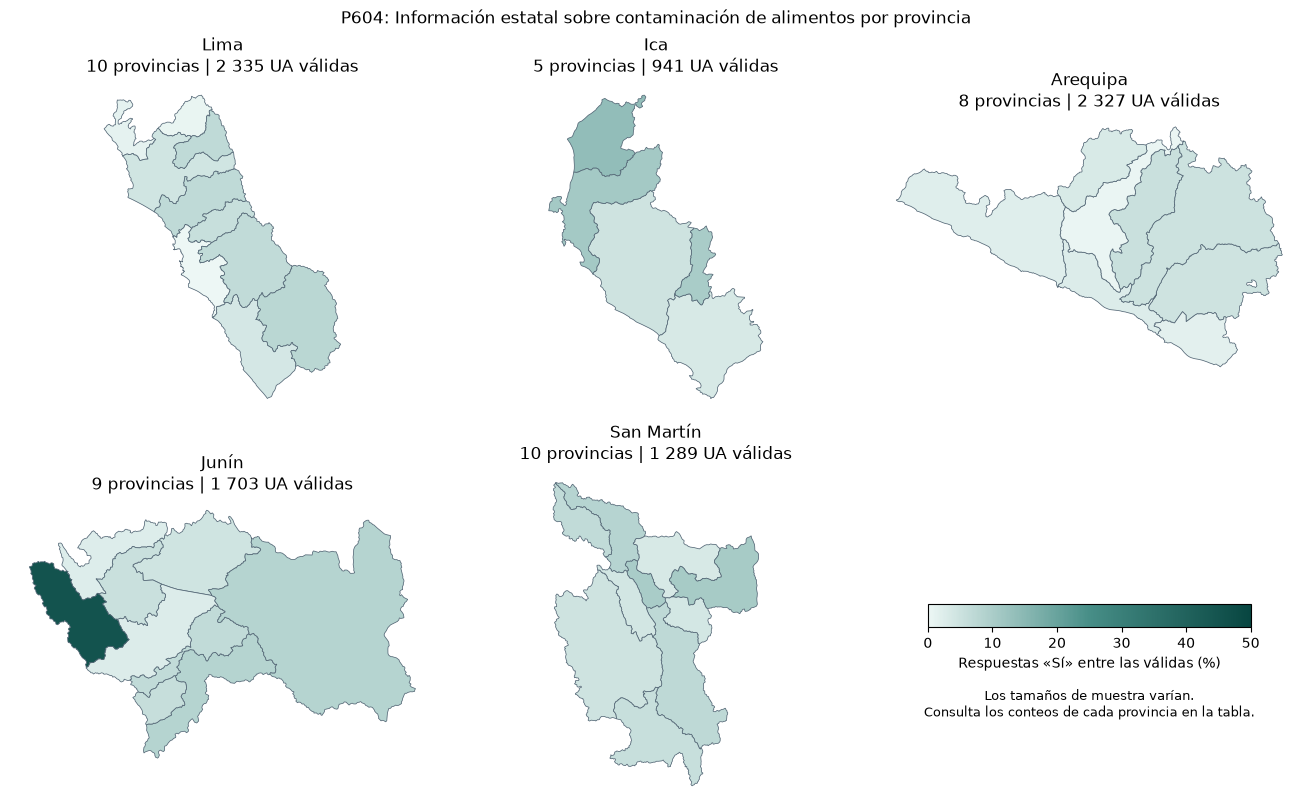

In [62]:
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.path import Path
from matplotlib.patches import PathPatch

# Una misma escala de porcentajes para comparar los cinco departamentos.
colores = LinearSegmentedColormap.from_list("P604", ["#edf7f5", "#478e87", "#084641"])
maximo_mapa = min(100, max(5, 5 * (int(mapa_p604_provincia["Sí (%)"].max()) // 5 + 1)))
escala_mapa = Normalize(vmin=0, vmax=maximo_mapa)
fig, ejes = plt.subplots(2, 3, figsize=(13, 8), layout="constrained")
for ax, (codigo, departamento) in zip(ejes.flat, departamentos_mapa.items()):
    provincias = mapa_p604_provincia.loc[mapa_p604_provincia["CCDD"].eq(codigo)]
    for geometria, porcentaje in provincias[["geometría", "Sí (%)"]].itertuples(index=False, name=None):
        assert geometria["type"] in ("Polygon", "MultiPolygon")
        poligonos = geometria["coordinates"]
        if geometria["type"] == "Polygon":
            poligonos = [poligonos]
        for poligono in poligonos:
            anillos = [
                Path(anillo, [Path.MOVETO] + [Path.LINETO] * (len(anillo) - 2) + [Path.CLOSEPOLY])
                for anillo in poligono
            ]
            ax.add_patch(PathPatch(
                Path.make_compound_path(*anillos), facecolor=colores(escala_mapa(porcentaje)),
                edgecolor="#546776", linewidth=0.55
            ))
    ax.autoscale_view()
    ax.set_aspect("equal")
    ax.set_title(f"{departamento}\n{len(provincias)} provincias | {provincias['Total válido'].sum():,} UA válidas".replace(",", " "))
    ax.set_axis_off()

leyenda = ejes.flat[-1]
leyenda.set_axis_off()
barra = fig.colorbar(plt.cm.ScalarMappable(norm=escala_mapa, cmap=colores),
                   cax=leyenda.inset_axes([0.12, 0.52, 0.76, 0.07]), orientation="horizontal")
barra.set_label("Respuestas «Sí» entre las válidas (%)")
leyenda.text(0.5, 0.29, "Los tamaños de muestra varían.\nConsulta los conteos de cada provincia en la tabla.",
             ha="center", va="center", fontsize=9, transform=leyenda.transAxes)
fig.suptitle("P604: Información estatal sobre contaminación de alimentos por provincia")
plt.show()

**Interpretación.** En Ica, Chincha registró 21 de 152 respuestas afirmativas (13,82 %), frente a 4 de 118 en Nasca (3,39 %). En el departamento de Lima, Yauyos registró 16 de 210 (7,62 %) y la provincia de Lima, 0 de 68. En Arequipa, Castilla registró 17 de 303 (5,61 %) y Condesuyos, 1 de 174 (0,57 %). En San Martín, la provincia del mismo nombre registró 11 de 103 (10,68 %) y Lamas, 6 de 175 (3,43 %). En Junín, Yauli tuvo 5 de 11 (45,45 %). Ese porcentaje se apoya en solo 11 respuestas. El mapa muestra información recibida según lo declarado, sin medir el alcance de los servicios estatales sobre toda la población.

**Auditoría.** Los 42 códigos provinciales coincidieron, con 479 «Sí» entre 8.595 respuestas válidas. La unión usa `CCDD + CCPP` frente a `IDPROV`. El nombre de Cañete se corrigió solo para mostrarlo. La comparación por provincias amplía el resultado por departamento de la sección 7.3, sin usar datos de Carátula.

### 7.15. P604 y P605A: Información estatal y conocimiento de límites por región

**Pregunta.** Dentro de cada región natural, ¿qué proporción declaró conocer los límites máximos de contaminantes entre quienes recibieron información estatal y entre quienes no la recibieron?

Usamos las UA con respuesta válida en ambas preguntas y código regional reconocido. En cada grupo regional de `P604`, dividimos quienes respondieron «Sí» en `P605A` entre el total válido de ese grupo. La diferencia se expresa en puntos porcentuales.

In [54]:
# Partir de las respuestas válidas en las dos preguntas de la sección 7.4.
datos_limites_region = datos_conocimiento.loc[datos_conocimiento["REGION"].isin(regiones_naturales)]
tabla_limites_region = pd.crosstab(
    [datos_limites_region["REGION"], datos_limites_region["P604"]],
    datos_limites_region["P605A"],
).reindex(
    index=pd.MultiIndex.from_product([list(regiones_naturales), [1, 2]], names=["REGION", "P604"]),
    columns=[1, 2], fill_value=0,
).rename(columns={1: "Conoce límites", 2: "No conoce límites"}).rename_axis(columns=None)
tabla_limites_region["Total válido"] = tabla_limites_region[["Conoce límites", "No conoce límites"]].sum(axis=1)
proporcion_limites_region = (
    100 * tabla_limites_region["Conoce límites"] / tabla_limites_region["Total válido"]
)
tabla_limites_region["Conoce (%)"] = proporcion_limites_region.round(2)

diferencias_limites_region = proporcion_limites_region.unstack("P604")
diferencias_limites_region = (
    diferencias_limites_region[1] - diferencias_limites_region[2]
).round(2).rename("Diferencia (puntos porcentuales)").rename(index=regiones_naturales).rename_axis("Región natural")

grupos_informacion = {1: "Recibió información", 2: "No recibió información"}
print("Respuestas válidas en ambas preguntas:", len(datos_conocimiento),
      "| Sin región reconocida:", len(datos_conocimiento) - len(datos_limites_region))
display(tabla_limites_region.rename(index=regiones_naturales, level="REGION").rename(
    index=grupos_informacion, level="P604"
).rename_axis(index=["Región natural", "Información estatal (P604)"]))
display(diferencias_limites_region.to_frame())

Respuestas válidas en ambas preguntas: 38449 | Sin región reconocida: 0


Conoce límites  No conoce límites  \
Región natural Información estatal (P604)                                      
Costa          Recibió información                    238                311   
               No recibió información                 844               7406   
Sierra         Recibió información                    244                795   
               No recibió información                 852              20547   
Selva          Recibió información                    128                256   
               No recibió información                 418               6410   

                                           Total válido  Conoce (%)  
Región natural Información estatal (P604)                            
Costa          Recibió información                  549       43.35  
               No recibió información              8250       10.23  
Sierra         Recibió información                 1039       23.48  
               No recibió información             21399        3.98  
Selva          Recibió información                  384       33.33  
               No recibió información              6828        6.12

,Diferencia (puntos porcentuales)
Región natural,
Costa,33.12
Sierra,19.50
Selva,27.21


**Interpretación.** En las tres regiones, la proporción que declaró conocer los límites fue mayor entre quienes recibieron información. La diferencia fue de 33,12 puntos en Costa (43,35 % frente a 10,23 %), 27,21 en Selva y 19,50 en Sierra. La encuesta muestra una diferencia entre grupos y por sí sola no permite saber si la información la explica.

**Auditoría.** Los seis grupos suman 38.449 UA y reproducen los conteos del cruce general de la sección 7.4. Separar por región muestra que la diferencia observada en el total también aparece en cada región y que su tamaño varía.

### 7.16. P601_4: Uso de residuos agrícolas como abono por región

**Pregunta.** ¿Cómo cambia entre Costa, Sierra y Selva la proporción de UA agrícolas que declaró usar residuos de cultivos como abono?

Se usa la misma base válida del análisis 6. En esa base, `P601_4 = 1` significa que la opción se marcó y `0`, que no se marcó. Calculamos el porcentaje sobre todas las UA válidas de cada región, incluidas las que marcaron otras prácticas.

In [55]:
region_abono = df_analisis.loc[marcas_p601.index, "REGION"]
region_abono_valida = region_abono.isin(regiones_naturales)
tabla_abono_region = pd.crosstab(
    region_abono.loc[region_abono_valida], marcas_p601.loc[region_abono_valida, "P601_4"]
).reindex(
    index=list(regiones_naturales), columns=[True, False], fill_value=0,
).rename(index=regiones_naturales, columns={True: "Marcó abono", False: "No marcó"}).rename_axis(
    index="Región natural", columns=None
)
tabla_abono_region["Total válido"] = tabla_abono_region[["Marcó abono", "No marcó"]].sum(axis=1)
tabla_abono_region["Marcó abono (%)"] = (
    100 * tabla_abono_region["Marcó abono"] / tabla_abono_region["Total válido"]
).round(2)
print("UA válidas del análisis 6:", n_p601, "| Sin región reconocida:", (~region_abono_valida).sum())
display(tabla_abono_region)

UA válidas del análisis 6: 38373 | Sin región reconocida: 0


,Marcó abono,No marcó,Total válido,Marcó abono (%)
Región natural,,,,
Costa,2655,6097,8752,30.34
Sierra,7509,14910,22419,33.49
Selva,1289,5913,7202,17.90


**Interpretación.** Marcaron la opción de abono 7.509 de 22.419 UA en Sierra (33,49 %), 2.655 de 8.752 en Costa (30,34 %) y 1.289 de 7.202 en Selva (17,90 %). La respuesta indica que se declaró la práctica. La encuesta no registra aquí cuánto residuo se aprovechó.

**Auditoría.** Las regiones suman las 38.373 UA válidas y las 11.453 que marcaron abono en el análisis 6. El total de 29,85 % de ese análisis no muestra la diferencia entre regiones.

### 7.17. P606_2 y P607: Almacenamiento a la intemperie y conocimiento del requisito de identificación

**Pregunta.** ¿Qué proporción declaró conocer el requisito de identificación de productos primarios entre quienes marcaron almacenamiento a la intemperie y quienes no marcaron esa opción?

Se incluyen las UA con respuesta válida en el bloque `P606` y con «Sí» o «No» en `P607`. En el primer bloque, `P606_2 = 1` indica que se marcó «A la intemperie» y `0`, que no se marcó. Las UA pudieron seleccionar más de un lugar. En cada grupo, el denominador es su total de UA y el numerador las que declararon conocer el requisito.

In [56]:
p607_almacenamiento = df_analisis.loc[marcas_p606.index, "P607"]
validas_almacenamiento = p607_almacenamiento.isin([1, 2])

tabla_p607_almacenamiento = pd.crosstab(
    marcas_p606.loc[validas_almacenamiento, "P606_2"],
    p607_almacenamiento.loc[validas_almacenamiento],
).reindex(index=[True, False], columns=[1, 2], fill_value=0).rename(
    index={True: "Marcó intemperie", False: "No marcó intemperie"},
    columns={1: "Conoce requisito", 2: "No conoce requisito"}
).rename_axis(index="Opción de almacenamiento", columns=None)
tabla_p607_almacenamiento["Total válido"] = tabla_p607_almacenamiento[
    ["Conoce requisito", "No conoce requisito"]
].sum(axis=1)
tabla_p607_almacenamiento["Conoce (%)"] = (
    100 * tabla_p607_almacenamiento["Conoce requisito"] / tabla_p607_almacenamiento["Total válido"]
).round(2)
print("UA válidas del análisis 9:", n_p606, "| Sin respuesta válida en P607:", (~validas_almacenamiento).sum())
display(tabla_p607_almacenamiento)

UA válidas del análisis 9: 37202 | Sin respuesta válida en P607: 0


,Conoce requisito,No conoce requisito,Total válido,Conoce (%)
Opción de almacenamiento,,,,
Marcó intemperie,610,3588,4198,14.53
No marcó intemperie,5866,27138,33004,17.77


**Interpretación.** Declararon conocer el requisito 610 de 4.198 UA que marcaron intemperie (14,53 %) y 5.866 de 33.004 entre quienes no marcaron esa opción (17,77 %). La diferencia observada es de 3,24 puntos porcentuales. La tabla combina dos respuestas declaradas y no demuestra que el lugar de almacenamiento influya en el conocimiento o al revés.

**Auditoría.** Los grupos suman 37.202 UA y las 6.476 respuestas «Sí» de `P607`. El grupo que marcó intemperie coincide con las 4.198 UA del análisis 9. Aquí se relaciona la práctica con el conocimiento dentro de los mismos registros.

## 8. Comprobaciones finales

Comprobamos que cada porcentaje use el número correcto de respuestas y que los subtotales coincidan con sus totales de referencia. Las salidas de esta versión se generaron al ejecutar el cuaderno con el archivo Parquet original desde un kernel limpio.

In [57]:
# Comprobar que los datos originales no cambiaron
datos_originales = pd.read_parquet("../data/raw/14_CAP600.parquet")

print("Datos originales sin cambios:", df_inocuidad.equals(datos_originales))

# Comprobar las respuestas válidas de la sección 7.1
print("Denominadores de 7.1:", (
    resumen_inocuidad["si"] + resumen_inocuidad["no"] == resumen_inocuidad["validas"]
).all())

# Comprobar los totales de las tablas territoriales
print("Totales de 7.2:", tabla_region["Total válido"].sum() == len(datos_region))
print("Totales de 7.3:", tabla_departamento["Total válido"].sum() == len(p604_departamento))

# Comprobar el cruce de información y conocimiento
print("Totales de 7.4:", tabla_conocimiento["Total válido"].sum() == len(datos_conocimiento))

# Comprobar las modalidades de certificación
print("Totales de 7.5:", tabla_certificacion["Frecuencia"].sum() == len(modalidades))

Datos originales sin cambios: True
Denominadores de 7.1: True
Totales de 7.2: True
Totales de 7.3: True
Totales de 7.4: True
Totales de 7.5: True


In [58]:
# Comprobar que los porcentajes estén entre 0 y 100
print("Porcentajes de 7.1:", resumen_inocuidad["porcentaje_si"].dropna().between(0, 100).all())

print("Porcentajes de 7.2:", tabla_region["Porcentaje Sí"].dropna().between(0, 100).all())

print("Porcentajes de 7.3:", tabla_departamento["Porcentaje Sí"].dropna().between(0, 100).all())

print("Porcentajes de 7.4:", tabla_conocimiento["Porcentaje Sí"].dropna().between(0, 100).all())

print("Porcentajes de 7.5:", tabla_certificacion["Porcentaje"].dropna().between(0, 100).all())

Porcentajes de 7.1: True
Porcentajes de 7.2: True
Porcentajes de 7.3: True
Porcentajes de 7.4: True
Porcentajes de 7.5: True


In [59]:
# Comprobar la distribución de modalidades de certificación
if len(modalidades) > 0:
    total_porcentaje = tabla_certificacion["Porcentaje"].sum()

    print("Suma de porcentajes:", total_porcentaje)
    print("Suma aproximadamente 100 %:", abs(total_porcentaje - 100) <= 0.02)
else:
    print("No hay modalidades válidas para calcular porcentajes.")

Suma de porcentajes: 100.0
Suma aproximadamente 100 %: True


In [60]:
# Análisis 6 a 13: contrastar las bases, los conteos y los porcentajes mostrados.
comprobaciones = {}
for numero, tabla, marcas, elegibles in [
    (6, tabla_p601, marcas_p601, elegibles_p601.sum()),
    (7, tabla_p602, marcas_p602, elegibles_p602.sum()),
    (8, tabla_p605, marcas_p605, resumen_inocuidad.loc["P604", "si"]),
    (9, tabla_p606, marcas_p606, elegibles_p606.sum()),
    (11, tabla_p610, marcas_p610, resumen_inocuidad.loc["P608", "si"]),
]:
    comprobaciones[numero] = (
        len(marcas) == elegibles
        and tabla["UA válidas"].eq(len(marcas)).all()
        and tabla["UA que marcaron"].eq(marcas.sum()).all()
        and tabla["Porcentaje (%)"].eq((100 * tabla["UA que marcaron"] / len(marcas)).round(2)).all()
    )

for numero, variable, tabla in [
    (10, "P607", tabla_p607_region),
    (12, "P608", tabla_p608_region),
    (13, "P603", tabla_p603_departamento),
]:
    comprobaciones[numero] = (
        tabla[["Sí", "No", "Total válido"]].sum().tolist()
        == resumen_inocuidad.loc[variable, ["si", "no", "validas"]].tolist()
        and tabla["Total válido"].eq(tabla["Sí"] + tabla["No"]).all()
        and tabla["Sí (%)"].eq((100 * tabla["Sí"] / tabla["Total válido"]).round(2)).all()
    )

display(pd.Series(comprobaciones, name="Comprobado").sort_index().rename_axis("Análisis").to_frame())
assert all(comprobaciones.values()), "Revisar las comprobaciones de los análisis 6 a 13."

,Comprobado
Análisis,
6,True
7,True
8,True
9,True
10,True
11,True
12,True
13,True


In [61]:
# Análisis 14 a 17: comprobar la unión y recuperar los totales anteriores.
totales_provinciales = tabla_p604_provincia.groupby("Departamento")[["Sí", "No", "Total válido"]].sum()
nombres_departamento_mapa = p604_provincia[["NOMBREDD", "CCDD"]].drop_duplicates().set_index("NOMBREDD")["CCDD"].map(departamentos_mapa)
totales_departamentales = tabla_departamento[["Sí", "No", "Total válido"]].rename(
    index=nombres_departamento_mapa
).reindex(totales_provinciales.index)

totales_limites = tabla_limites_region.groupby(level="P604")[
    ["Conoce límites", "No conoce límites", "Total válido"]
].sum().rename(index=grupos_informacion)

comprobaciones_nuevas = {
    14: mapa_p604_provincia["_merge"].eq("both").all()
        and totales_provinciales.eq(totales_departamentales).all().all(),
    15: totales_limites.eq(tabla_conocimiento[totales_limites.columns]).all().all(),
    16: tabla_abono_region["Total válido"].sum() == n_p601
        and tabla_abono_region["Marcó abono"].sum() == tabla_p601.loc["P601_4", "UA que marcaron"],
    17: tabla_p607_almacenamiento["Total válido"].sum() == n_p606
        and tabla_p607_almacenamiento["Conoce requisito"].sum() == resumen_inocuidad.loc["P607", "si"]
        and tabla_p607_almacenamiento.loc["Marcó intemperie", "Total válido"] == tabla_p606.loc["P606_2", "UA que marcaron"],
}
display(pd.Series(comprobaciones_nuevas, name="Comprobado").rename_axis("Análisis").to_frame())
assert all(comprobaciones_nuevas.values()), "Revisar las comprobaciones de los análisis 14 a 17."

,Comprobado
Análisis,
14,True
15,True
16,True
17,True


Las comprobaciones permiten revisar la conservación de los datos originales, la consistencia de los denominadores y los rangos de los % calculados.